# NUCLE feature ablation and masking — validation report

**Run date:** 2026-10-17  
**Scope:** models fit on train; validation selects configurations; the held-out test partition was not scored.

This run compares the incremental sequence S+L → S+L+P → S+L+P+M → S+L+P+M+D, plus target-span lexical masking and the non-lexical S+P+M+D condition. Every condition tunes the existing LR C/class-weight grid and Tree depth/leaf/class-weight grid. The masking encoder was rebuilt after masking on train rows; lexical context outside the span remains. The run contains 120 fits (11,052 train, 2,368 validation) and took 21.7 minutes.

The first masked-feature pass was discarded after auditing which encoded fields contained span lexical identity; only the corrected masking run is included in the results and runtime. The other five variants are retained from the original full benchmark run.

Feature manifest SHA-256: `95bdd11bc82d59438c9b643868ec54d920ab14c59c00404cb7b92649a5a0b3b6`  
Split manifest SHA-256: `c3a65115ad93c837372e1c72d186b244043b711ee41a6706b13ccacea8be5677`  
LR configurations that did not converge and were excluded from selection: 10/48.

## Selected validation results

| Variant | Features | Model | Selected configuration | Macro-F1 | Accuracy | Train accuracy |
|---|---:|---|---|---:|---:|---:|
| S+L | 9,203 | LR | `{'C': 1.0, 'class_weight': None}` | 0.7164 | 0.7800 | 0.9378 |
| S+L | 9,203 | Tree | `{'max_depth': 12, 'min_samples_leaf': 5, 'class_weight': None}` | 0.5832 | 0.6643 | 0.6940 |
| S+L+P | 15,271 | LR | `{'C': 1.0, 'class_weight': None}` | 0.7956 | 0.8395 | 0.9732 |
| S+L+P | 15,271 | Tree | `{'max_depth': 12, 'min_samples_leaf': 5, 'class_weight': None}` | 0.7548 | 0.8041 | 0.8341 |
| S+L+P+M | 15,302 | LR | `{'C': 1.0, 'class_weight': None}` | 0.8048 | 0.8438 | 0.9716 |
| S+L+P+M | 15,302 | Tree | `{'max_depth': 12, 'min_samples_leaf': 5, 'class_weight': 'balanced'}` | 0.7929 | 0.8264 | 0.8543 |
| S+L+P+M+D | 16,180 | LR | `{'C': 0.1, 'class_weight': None}` | 0.8067 | 0.8463 | 0.8906 |
| S+L+P+M+D | 16,180 | Tree | `{'max_depth': 8, 'min_samples_leaf': 5, 'class_weight': None}` | 0.7879 | 0.8142 | 0.8350 |
| Full_mask_span_lexical | 16,180 | LR | `{'C': 0.1, 'class_weight': None}` | 0.8016 | 0.8387 | 0.8810 |
| Full_mask_span_lexical | 16,180 | Tree | `{'max_depth': 12, 'min_samples_leaf': 5, 'class_weight': 'balanced'}` | 0.7876 | 0.8214 | 0.8543 |
| S+P+M+D_nonlexical | 6,986 | LR | `{'C': 1.0, 'class_weight': None}` | 0.7964 | 0.8311 | 0.9013 |
| S+P+M+D_nonlexical | 6,986 | Tree | `{'max_depth': 8, 'min_samples_leaf': 20, 'class_weight': 'balanced'}` | 0.7862 | 0.8167 | 0.8253 |

The best full-feature results are LR Macro-F1 **0.8067** and Tree **0.7879**. Both selected unweighted configurations.

## Findings

- Adding P to S+L changes Macro-F1 by **+0.0791** for LR and **+0.1716** for Tree. It gives the largest gain in the incremental sequence for both models.
- Adding M after P changes Macro-F1 by **+0.0093** for LR and **+0.0381** for Tree.
- Adding D after M changes Macro-F1 by **+0.0019** for LR and **-0.0051** for Tree. These are sequential tuned comparisons, not isolated causal effects.
- Masking target-span lexical identity scores **0.8016** LR and **0.7876** Tree. The difference from full features is **-0.0051** and **-0.0002** respectively.
- Removing all lexical features scores **0.7964** LR and **0.7862** Tree. The full-to-nonlexical difference is **-0.0103** and **-0.0017**.
- The class-weight table below compares the best converged configuration under `None` and `balanced` for every variant/model. Balanced weights help selected Tree variants, but not the selected full-feature model; LR selects unweighted in all six variants.

## Detailed tables and charts

The notebook displays the selected-config table, per-weight comparison, per-class F1 for the full models, and three charts. Embedded values are aggregate metrics only; no source sentences or sample IDs are included.

## Limits and next step

Each feature condition selects hyperparameters on the same validation set, so the differences are validation model-selection evidence rather than an unbiased final estimate. Test remains unopened. Next, freeze the feature/model protocol using validation, then score test once.

To rerun the benchmark and regenerate this notebook from its local aggregate report, run `python src/training/nucle_ablation.py`, then `python src/reporting/build_ablation_notebook.py` from the project root.


120 fits | 11,052 train | 2,368 validation | 21.7 min | test scored: False
               Variant  Features              Model                                                      Selected config  Val Macro-F1  Val accuracy  Train accuracy
                   S+L      9203 LogisticRegression                                     {'C': 1.0, 'class_weight': None}        0.7164        0.7800          0.9378
                   S+L      9203       DecisionTree       {'max_depth': 12, 'min_samples_leaf': 5, 'class_weight': None}        0.5832        0.6643          0.6940
                 S+L+P     15271 LogisticRegression                                     {'C': 1.0, 'class_weight': None}        0.7956        0.8395          0.9732
                 S+L+P     15271       DecisionTree       {'max_depth': 12, 'min_samples_leaf': 5, 'class_weight': None}        0.7548        0.8041          0.8341
               S+L+P+M     15302 LogisticRegression                                     {'C': 1.0, '

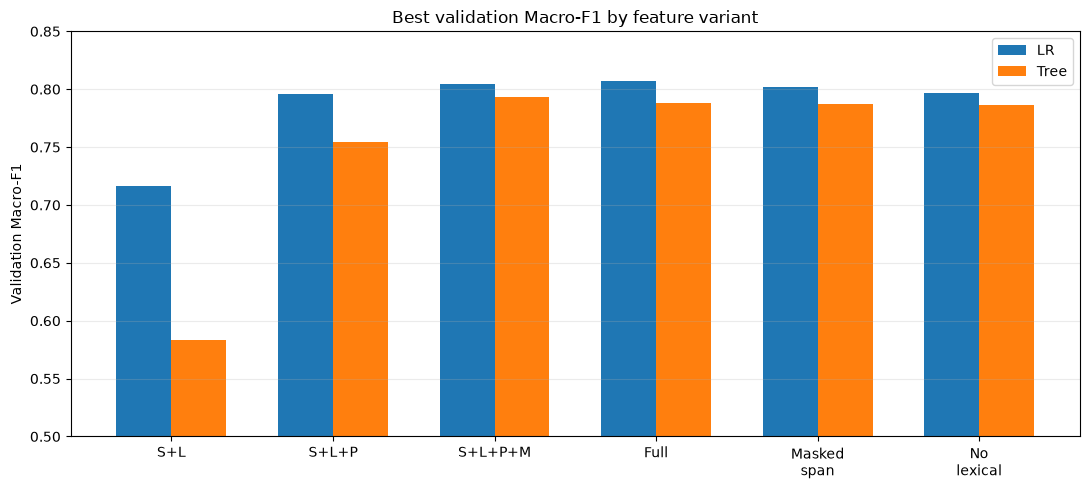

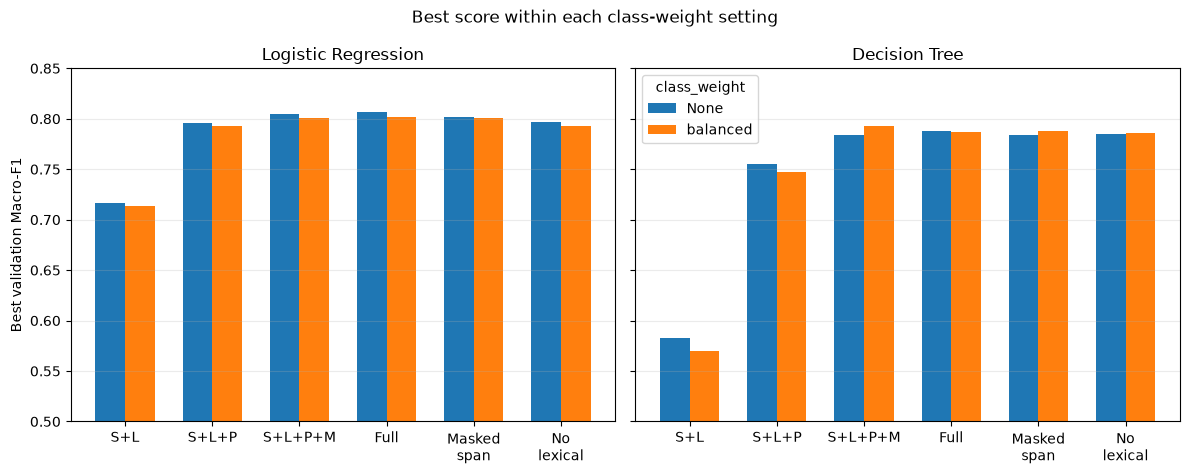

Model        LR   Tree
Label                 
ArtOrDet 0.8928 0.8488
Nn       0.8383 0.7887
Prep     0.9114 0.9034
SVA      0.7566 0.7664
Vform    0.6343 0.6321


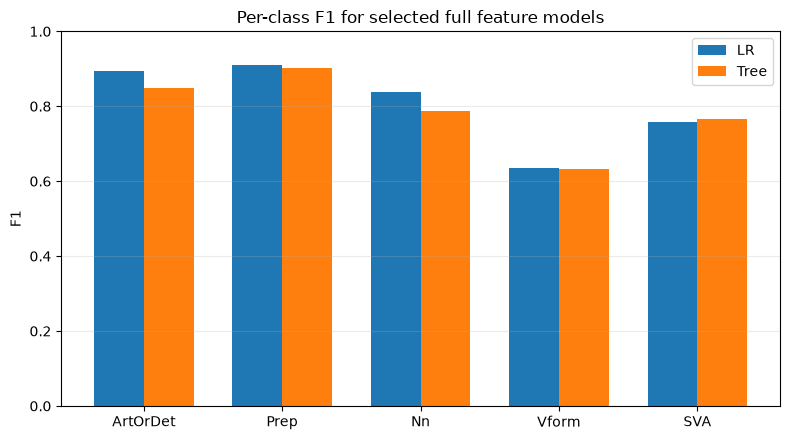

In [2]:
import json
import pandas as pd
import matplotlib.pyplot as plt

REPORT = json.loads('{"feature_schema":"nucle-slpmd-v1","feature_manifest_sha256":"95bdd11bc82d59438c9b643868ec54d920ab14c59c00404cb7b92649a5a0b3b6","split_manifest_sha256":"c3a65115ad93c837372e1c72d186b244043b711ee41a6706b13ccacea8be5677","fit_partition":"train","selection_partition":"validation","test_scored":false,"train_samples":11052,"validation_samples":2368,"variant_feature_counts":{"S+L":9203,"S+L+P":15271,"S+L+P+M":15302,"S+L+P+M+D":16180,"Full_mask_span_lexical":16180,"S+P+M+D_nonlexical":6986},"selected_by_validation":{"S+L":{"LogisticRegression":{"configuration":{"C":1.0,"class_weight":null},"validation_macro_f1":0.7164489754008861,"validation_accuracy":0.7799831081081081,"train_accuracy":0.9378393051031487,"converged":true},"DecisionTree":{"configuration":{"max_depth":12,"min_samples_leaf":5,"class_weight":null},"validation_macro_f1":0.583205550445814,"validation_accuracy":0.6642736486486487,"train_accuracy":0.6939920376402461,"converged":true}},"S+L+P":{"LogisticRegression":{"configuration":{"C":1.0,"class_weight":null},"validation_macro_f1":0.7955568392069893,"validation_accuracy":0.839527027027027,"train_accuracy":0.9732175171914585,"converged":true},"DecisionTree":{"configuration":{"max_depth":12,"min_samples_leaf":5,"class_weight":null},"validation_macro_f1":0.7548243893585442,"validation_accuracy":0.8040540540540541,"train_accuracy":0.8340571842200507,"converged":true}},"S+L+P+M":{"LogisticRegression":{"configuration":{"C":1.0,"class_weight":null},"validation_macro_f1":0.8048297252438402,"validation_accuracy":0.84375,"train_accuracy":0.9715888526963445,"converged":true},"DecisionTree":{"configuration":{"max_depth":12,"min_samples_leaf":5,"class_weight":"balanced"},"validation_macro_f1":0.7929483279100042,"validation_accuracy":0.8264358108108109,"train_accuracy":0.8543250090481361,"converged":true}},"S+L+P+M+D":{"LogisticRegression":{"configuration":{"C":0.1,"class_weight":null},"validation_macro_f1":0.8066825148760056,"validation_accuracy":0.8462837837837838,"train_accuracy":0.8906080347448425,"converged":true},"DecisionTree":{"configuration":{"max_depth":8,"min_samples_leaf":5,"class_weight":null},"validation_macro_f1":0.7878706585346912,"validation_accuracy":0.8141891891891891,"train_accuracy":0.8349619978284474,"converged":true}},"Full_mask_span_lexical":{"LogisticRegression":{"configuration":{"C":0.1,"class_weight":null},"validation_macro_f1":0.8015728310801785,"validation_accuracy":0.8386824324324325,"train_accuracy":0.8810170104958378,"converged":true},"DecisionTree":{"configuration":{"max_depth":12,"min_samples_leaf":5,"class_weight":"balanced"},"validation_macro_f1":0.7876273162782839,"validation_accuracy":0.8213682432432432,"train_accuracy":0.8543250090481361,"converged":true}},"S+P+M+D_nonlexical":{"LogisticRegression":{"configuration":{"C":1.0,"class_weight":null},"validation_macro_f1":0.7963795069078647,"validation_accuracy":0.831081081081081,"train_accuracy":0.9012848353239232,"converged":true},"DecisionTree":{"configuration":{"max_depth":8,"min_samples_leaf":20,"class_weight":"balanced"},"validation_macro_f1":0.7862164576147477,"validation_accuracy":0.816722972972973,"train_accuracy":0.825280492218603,"converged":true}}},"fit_count":120,"runtime_seconds":1300.765889100032,"started_at_utc":"2026-10-17T08:07:44.035+00:00","finished_at_utc":"2026-10-17T08:34:44.956+00:00","masking_specification":{"applied_before_train_only_encoder_fit":true,"masked_fields":["L|span_unigrams","direct target-span terms within L|span_ngrams"],"retained_fields":["lexical unigram/bigram terms from up to two tokens outside the full span on each side","all S/P/M/D features"],"vocabulary_fit_partition":"train","test_scored":false,"method":"Re-extracted source rows; replaced span lexical fields with the fixed missing marker and rebuilt the lexical term channel from left/right context only before fitting the variant encoder."},"results":[{"variant":"S+L","description":"Incremental baseline","model":"LogisticRegression","configuration":{"C":0.01,"class_weight":null},"feature_count":9203,"fit_seconds":4.408739499980584,"train_accuracy":0.66576185305827,"macro_f1":0.48876527048315116,"accuracy":0.6418918918918919,"per_label":{"ArtOrDet":{"precision":0.6151761517615176,"recall":0.9116465863453815,"f1":0.7346278317152103,"support":996},"Prep":{"precision":0.6772334293948127,"recall":0.649171270718232,"f1":0.6629055007052186,"support":362},"Nn":{"precision":0.6752136752136753,"recall":0.5592920353982301,"f1":0.6118102613746371,"support":565},"Vform":{"precision":0.5,"recall":0.037037037037037035,"f1":0.06896551724137931,"support":216},"SVA":{"precision":0.8688524590163934,"recall":0.2314410480349345,"f1":0.36551724137931035,"support":229}},"convergence":{"iterations":109,"iterations_max":1000,"closure_evaluations":115,"max_evaluations":1250,"final_objective":1.11033296585083,"gradient_inf_norm":0.0001159901003120467,"tolerance_grad":1e-06,"tolerance_change":1e-09,"termination":"change_tolerance","converged":true}},{"variant":"S+L","description":"Incremental baseline","model":"LogisticRegression","configuration":{"C":0.01,"class_weight":"balanced"},"feature_count":9203,"fit_seconds":2.7862027999944985,"train_accuracy":0.6614187477379659,"macro_f1":0.5818323651307645,"accuracy":0.6266891891891891,"per_label":{"ArtOrDet":{"precision":0.8502024291497976,"recall":0.6325301204819277,"f1":0.7253886010362693,"support":996},"Prep":{"precision":0.5425925925925926,"recall":0.8093922651933702,"f1":0.6496674057649667,"support":362},"Nn":{"precision":0.6528066528066528,"recall":0.5557522123893806,"f1":0.6003824091778202,"support":565},"Vform":{"precision":0.3772893772893773,"recall":0.47685185185185186,"f1":0.4212678936605317,"support":216},"SVA":{"precision":0.43243243243243246,"recall":0.62882096069869,"f1":0.5124555160142348,"support":229}},"convergence":{"iterations":108,"iterations_max":1000,"closure_evaluations":118,"max_evaluations":1250,"final_objective":1.2445156574249268,"gradient_inf_norm":0.00045826000859960914,"tolerance_grad":1e-06,"tolerance_change":1e-09,"termination":"change_tolerance","converged":true}},{"variant":"S+L","description":"Incremental baseline","model":"LogisticRegression","configuration":{"C":0.1,"class_weight":null},"feature_count":9203,"fit_seconds":5.4007780000101775,"train_accuracy":0.813336952587767,"macro_f1":0.6746199760976817,"accuracy":0.7525337837837838,"per_label":{"ArtOrDet":{"precision":0.7635893011216566,"recall":0.8885542168674698,"f1":0.8213457076566124,"support":996},"Prep":{"precision":0.7984084880636605,"recall":0.8314917127071824,"f1":0.8146143437077132,"support":362},"Nn":{"precision":0.7328519855595668,"recall":0.7185840707964601,"f1":0.7256478999106344,"support":565},"Vform":{"precision":0.55,"recall":0.25462962962962965,"f1":0.34810126582278483,"support":216},"SVA":{"precision":0.7584269662921348,"recall":0.5895196506550219,"f1":0.6633906633906633,"support":229}},"convergence":{"iterations":205,"iterations_max":1000,"closure_evaluations":209,"max_evaluations":1250,"final_objective":0.7728911638259888,"gradient_inf_norm":0.00044338798034004867,"tolerance_grad":1e-06,"tolerance_change":1e-09,"termination":"change_tolerance","converged":true}},{"variant":"S+L","description":"Incremental baseline","model":"LogisticRegression","configuration":{"C":0.1,"class_weight":"balanced"},"feature_count":9203,"fit_seconds":6.29837650002446,"train_accuracy":0.8089033659066233,"macro_f1":0.6832674483089923,"accuracy":0.730152027027027,"per_label":{"ArtOrDet":{"precision":0.8614318706697459,"recall":0.748995983935743,"f1":0.8012889366272825,"support":996},"Prep":{"precision":0.7341176470588235,"recall":0.861878453038674,"f1":0.7928843710292248,"support":362},"Nn":{"precision":0.7317518248175182,"recall":0.7097345132743362,"f1":0.7205750224618149,"support":565},"Vform":{"precision":0.4435483870967742,"recall":0.5092592592592593,"f1":0.47413793103448276,"support":216},"SVA":{"precision":0.5693950177935944,"recall":0.6986899563318777,"f1":0.6274509803921569,"support":229}},"convergence":{"iterations":219,"iterations_max":1000,"closure_evaluations":237,"max_evaluations":1250,"final_objective":0.8590357899665833,"gradient_inf_norm":0.0008867446449585259,"tolerance_grad":1e-06,"tolerance_change":1e-09,"termination":"change_tolerance","converged":true}},{"variant":"S+L","description":"Incremental baseline","model":"LogisticRegression","configuration":{"C":1.0,"class_weight":null},"feature_count":9203,"fit_seconds":12.508344599977136,"train_accuracy":0.9378393051031487,"macro_f1":0.7164489754008861,"accuracy":0.7799831081081081,"per_label":{"ArtOrDet":{"precision":0.8109360518999074,"recall":0.8785140562248996,"f1":0.8433734939759037,"support":996},"Prep":{"precision":0.8418230563002681,"recall":0.8674033149171271,"f1":0.854421768707483,"support":362},"Nn":{"precision":0.7710196779964222,"recall":0.7628318584070797,"f1":0.7669039145907474,"support":565},"Vform":{"precision":0.51875,"recall":0.38425925925925924,"f1":0.44148936170212766,"support":216},"SVA":{"precision":0.7309644670050761,"recall":0.62882096069869,"f1":0.6760563380281689,"support":229}},"convergence":{"iterations":433,"iterations_max":1000,"closure_evaluations":457,"max_evaluations":1250,"final_objective":0.4291539192199707,"gradient_inf_norm":9.65388971962966e-05,"tolerance_grad":1e-06,"tolerance_change":1e-09,"termination":"change_tolerance","converged":true}},{"variant":"S+L","description":"Incremental baseline","model":"LogisticRegression","configuration":{"C":1.0,"class_weight":"balanced"},"feature_count":9203,"fit_seconds":18.782349699991755,"train_accuracy":0.934220050669562,"macro_f1":0.7139021271897261,"accuracy":0.7647804054054054,"per_label":{"ArtOrDet":{"precision":0.8622174381054898,"recall":0.8042168674698795,"f1":0.8322077922077923,"support":996},"Prep":{"precision":0.8264248704663213,"recall":0.8812154696132597,"f1":0.8529411764705883,"support":362},"Nn":{"precision":0.7482517482517482,"recall":0.7575221238938054,"f1":0.752858399296394,"support":565},"Vform":{"precision":0.4658119658119658,"recall":0.5046296296296297,"f1":0.48444444444444446,"support":216},"SVA":{"precision":0.6234817813765182,"recall":0.6724890829694323,"f1":0.6470588235294119,"support":229}},"convergence":{"iterations":605,"iterations_max":1000,"closure_evaluations":656,"max_evaluations":1250,"final_objective":0.4533665180206299,"gradient_inf_norm":0.0005387577111832798,"tolerance_grad":1e-06,"tolerance_change":1e-09,"termination":"change_tolerance","converged":true}},{"variant":"S+L","description":"Incremental baseline","model":"LogisticRegression","configuration":{"C":10.0,"class_weight":null},"feature_count":9203,"fit_seconds":33.79087609995622,"train_accuracy":0.9931234165761853,"macro_f1":0.7144842403841273,"accuracy":0.7732263513513513,"per_label":{"ArtOrDet":{"precision":0.8113207547169812,"recall":0.8634538152610441,"f1":0.8365758754863812,"support":996},"Prep":{"precision":0.8555858310626703,"recall":0.8674033149171271,"f1":0.8614540466392319,"support":362},"Nn":{"precision":0.7617328519855595,"recall":0.7469026548672566,"f1":0.7542448614834674,"support":565},"Vform":{"precision":0.5055555555555555,"recall":0.4212962962962963,"f1":0.45959595959595956,"support":216},"SVA":{"precision":0.6956521739130435,"recall":0.62882096069869,"f1":0.6605504587155963,"support":229}},"convergence":{"iterations":1000,"iterations_max":1000,"closure_evaluations":1083,"max_evaluations":1250,"final_objective":0.16184505820274353,"gradient_inf_norm":0.00034913583658635616,"tolerance_grad":1e-06,"tolerance_change":1e-09,"termination":"iteration_limit","converged":false}},{"variant":"S+L","description":"Incremental baseline","model":"LogisticRegression","configuration":{"C":10.0,"class_weight":"balanced"},"feature_count":9203,"fit_seconds":35.98808220005594,"train_accuracy":0.989956568946797,"macro_f1":0.7084876104615393,"accuracy":0.7635135135135135,"per_label":{"ArtOrDet":{"precision":0.8386108273748724,"recall":0.8242971887550201,"f1":0.8313924050632913,"support":996},"Prep":{"precision":0.8445040214477212,"recall":0.8701657458563536,"f1":0.8571428571428572,"support":362},"Nn":{"precision":0.7553571428571428,"recall":0.7486725663716814,"f1":0.7520000000000001,"support":565},"Vform":{"precision":0.4577777777777778,"recall":0.47685185185185186,"f1":0.4671201814058957,"support":216},"SVA":{"precision":0.6320346320346321,"recall":0.6375545851528385,"f1":0.6347826086956523,"support":229}},"convergence":{"iterations":1000,"iterations_max":1000,"closure_evaluations":1084,"max_evaluations":1250,"final_objective":0.163882315158844,"gradient_inf_norm":0.00047439869376830757,"tolerance_grad":1e-06,"tolerance_change":1e-09,"termination":"iteration_limit","converged":false}},{"variant":"S+L","description":"Incremental baseline","model":"DecisionTree","configuration":{"max_depth":4,"min_samples_leaf":5,"class_weight":null},"feature_count":9203,"fit_seconds":0.7848696999717504,"train_accuracy":0.5740137531668477,"macro_f1":0.42531364791613974,"accuracy":0.559543918918919,"per_label":{"ArtOrDet":{"precision":0.533292608430055,"recall":0.8765060240963856,"f1":0.6631219141663502,"support":996},"Prep":{"precision":0.7556179775280899,"recall":0.7430939226519337,"f1":0.7493036211699164,"support":362},"Nn":{"precision":0.5446009389671361,"recall":0.20530973451327433,"f1":0.2982005141388175,"support":565},"Vform":{"precision":0.3902439024390244,"recall":0.07407407407407407,"f1":0.12451361867704279,"support":216},"SVA":{"precision":0.4214876033057851,"recall":0.22270742358078602,"f1":0.2914285714285714,"support":229}}},{"variant":"S+L","description":"Incremental baseline","model":"DecisionTree","configuration":{"max_depth":4,"min_samples_leaf":5,"class_weight":"balanced"},"feature_count":9203,"fit_seconds":0.5212836000137031,"train_accuracy":0.5522077452044879,"macro_f1":0.3974748685036001,"accuracy":0.5481418918918919,"per_label":{"ArtOrDet":{"precision":0.5146974063400577,"recall":0.8965863453815262,"f1":0.6539729036982791,"support":996},"Prep":{"precision":0.7472222222222222,"recall":0.7430939226519337,"f1":0.7451523545706371,"support":362},"Nn":{"precision":0.4810810810810811,"recall":0.15752212389380532,"f1":0.23733333333333334,"support":565},"Vform":{"precision":0.4090909090909091,"recall":0.08333333333333333,"f1":0.13846153846153844,"support":216},"SVA":{"precision":0.6590909090909091,"recall":0.12663755458515283,"f1":0.21245421245421245,"support":229}}},{"variant":"S+L","description":"Incremental baseline","model":"DecisionTree","configuration":{"max_depth":4,"min_samples_leaf":20,"class_weight":null},"feature_count":9203,"fit_seconds":0.6736566000618041,"train_accuracy":0.573108939558451,"macro_f1":0.4248252533478259,"accuracy":0.5591216216216216,"per_label":{"ArtOrDet":{"precision":0.532967032967033,"recall":0.8765060240963856,"f1":0.6628701594533029,"support":996},"Prep":{"precision":0.7556179775280899,"recall":0.7430939226519337,"f1":0.7493036211699164,"support":362},"Nn":{"precision":0.5424528301886793,"recall":0.20353982300884957,"f1":0.29601029601029605,"support":565},"Vform":{"precision":0.3902439024390244,"recall":0.07407407407407407,"f1":0.12451361867704279,"support":216},"SVA":{"precision":0.4214876033057851,"recall":0.22270742358078602,"f1":0.2914285714285714,"support":229}}},{"variant":"S+L","description":"Incremental baseline","model":"DecisionTree","configuration":{"max_depth":4,"min_samples_leaf":20,"class_weight":"balanced"},"feature_count":9203,"fit_seconds":0.4873797999462113,"train_accuracy":0.5532030401737242,"macro_f1":0.39412360975532373,"accuracy":0.549831081081081,"per_label":{"ArtOrDet":{"precision":0.516295025728988,"recall":0.9066265060240963,"f1":0.6579234972677596,"support":996},"Prep":{"precision":0.7450980392156863,"recall":0.7348066298342542,"f1":0.7399165507649513,"support":362},"Nn":{"precision":0.49444444444444446,"recall":0.15752212389380532,"f1":0.2389261744966443,"support":565},"Vform":{"precision":0.3829787234042553,"recall":0.08333333333333333,"f1":0.13688212927756654,"support":216},"SVA":{"precision":0.7428571428571429,"recall":0.11353711790393013,"f1":0.19696969696969696,"support":229}}},{"variant":"S+L","description":"Incremental baseline","model":"DecisionTree","configuration":{"max_depth":8,"min_samples_leaf":5,"class_weight":null},"feature_count":9203,"fit_seconds":1.1906996000325307,"train_accuracy":0.6483894317770539,"macro_f1":0.5330904041231189,"accuracy":0.6342905405405406,"per_label":{"ArtOrDet":{"precision":0.7251687560270009,"recall":0.7550200803212851,"f1":0.7397934087555336,"support":996},"Prep":{"precision":0.8323170731707317,"recall":0.7541436464088398,"f1":0.7913043478260869,"support":362},"Nn":{"precision":0.4495944380069525,"recall":0.6867256637168142,"f1":0.5434173669467788,"support":565},"Vform":{"precision":0.4716981132075472,"recall":0.11574074074074074,"f1":0.1858736059479554,"support":216},"SVA":{"precision":0.735632183908046,"recall":0.2794759825327511,"f1":0.4050632911392405,"support":229}}},{"variant":"S+L","description":"Incremental baseline","model":"DecisionTree","configuration":{"max_depth":8,"min_samples_leaf":5,"class_weight":"balanced"},"feature_count":9203,"fit_seconds":1.326836199965328,"train_accuracy":0.6549945711183496,"macro_f1":0.5583401507249353,"accuracy":0.6452702702702703,"per_label":{"ArtOrDet":{"precision":0.7242083758937692,"recall":0.7118473895582329,"f1":0.7179746835443038,"support":996},"Prep":{"precision":0.8324022346368715,"recall":0.8232044198895028,"f1":0.8277777777777778,"support":362},"Nn":{"precision":0.49228944246737844,"recall":0.7345132743362832,"f1":0.5894886363636364,"support":565},"Vform":{"precision":0.37349397590361444,"recall":0.14351851851851852,"f1":0.20735785953177258,"support":216},"SVA":{"precision":0.7142857142857143,"recall":0.32751091703056767,"f1":0.4491017964071856,"support":229}}},{"variant":"S+L","description":"Incremental baseline","model":"DecisionTree","configuration":{"max_depth":8,"min_samples_leaf":20,"class_weight":null},"feature_count":9203,"fit_seconds":1.1021649000467733,"train_accuracy":0.6319218241042345,"macro_f1":0.49026631742360066,"accuracy":0.6114864864864865,"per_label":{"ArtOrDet":{"precision":0.7187807276302851,"recall":0.7339357429718876,"f1":0.7262791852955787,"support":996},"Prep":{"precision":0.7685714285714286,"recall":0.7430939226519337,"f1":0.7556179775280899,"support":362},"Nn":{"precision":0.44418331374853115,"recall":0.6690265486725664,"f1":0.5338983050847458,"support":565},"Vform":{"precision":0.3611111111111111,"recall":0.06018518518518518,"f1":0.10317460317460317,"support":216},"SVA":{"precision":0.5,"recall":0.24890829694323144,"f1":0.3323615160349854,"support":229}}},{"variant":"S+L","description":"Incremental baseline","model":"DecisionTree","configuration":{"max_depth":8,"min_samples_leaf":20,"class_weight":"balanced"},"feature_count":9203,"fit_seconds":1.153527699992992,"train_accuracy":0.6421462178791169,"macro_f1":0.5399953143363279,"accuracy":0.6326013513513513,"per_label":{"ArtOrDet":{"precision":0.6995169082125604,"recall":0.7269076305220884,"f1":0.7129492860659773,"support":996},"Prep":{"precision":0.7908847184986595,"recall":0.8149171270718232,"f1":0.8027210884353743,"support":362},"Nn":{"precision":0.4921052631578947,"recall":0.6619469026548672,"f1":0.5645283018867925,"support":565},"Vform":{"precision":0.42857142857142855,"recall":0.125,"f1":0.19354838709677416,"support":216},"SVA":{"precision":0.5693430656934306,"recall":0.3406113537117904,"f1":0.4262295081967213,"support":229}}},{"variant":"S+L","description":"Incremental baseline","model":"DecisionTree","configuration":{"max_depth":12,"min_samples_leaf":5,"class_weight":null},"feature_count":9203,"fit_seconds":1.5498183999443427,"train_accuracy":0.6939920376402461,"macro_f1":0.583205550445814,"accuracy":0.6642736486486487,"per_label":{"ArtOrDet":{"precision":0.7060931899641577,"recall":0.7911646586345381,"f1":0.7462121212121212,"support":996},"Prep":{"precision":0.8364197530864198,"recall":0.7486187845303868,"f1":0.7900874635568513,"support":362},"Nn":{"precision":0.548480463096961,"recall":0.6707964601769911,"f1":0.6035031847133757,"support":565},"Vform":{"precision":0.37735849056603776,"recall":0.18518518518518517,"f1":0.2484472049689441,"support":216},"SVA":{"precision":0.7251908396946565,"recall":0.4148471615720524,"f1":0.5277777777777779,"support":229}}},{"variant":"S+L","description":"Incremental baseline","model":"DecisionTree","configuration":{"max_depth":12,"min_samples_leaf":5,"class_weight":"balanced"},"feature_count":9203,"fit_seconds":2.119145300006494,"train_accuracy":0.686663047412233,"macro_f1":0.5702829848724355,"accuracy":0.6490709459459459,"per_label":{"ArtOrDet":{"precision":0.7433155080213903,"recall":0.6977911646586346,"f1":0.7198342827550491,"support":996},"Prep":{"precision":0.8379120879120879,"recall":0.8425414364640884,"f1":0.8402203856749313,"support":362},"Nn":{"precision":0.49352179034157834,"recall":0.7415929203539823,"f1":0.5926449787835927,"support":565},"Vform":{"precision":0.3300970873786408,"recall":0.1574074074074074,"f1":0.213166144200627,"support":216},"SVA":{"precision":0.717948717948718,"recall":0.36681222707423583,"f1":0.48554913294797686,"support":229}}},{"variant":"S+L","description":"Incremental baseline","model":"DecisionTree","configuration":{"max_depth":12,"min_samples_leaf":20,"class_weight":null},"feature_count":9203,"fit_seconds":1.6714144999859855,"train_accuracy":0.6658523344191096,"macro_f1":0.5420440159993334,"accuracy":0.6351351351351351,"per_label":{"ArtOrDet":{"precision":0.6904332129963899,"recall":0.7680722891566265,"f1":0.7271863117870723,"support":996},"Prep":{"precision":0.7685714285714286,"recall":0.7430939226519337,"f1":0.7556179775280899,"support":362},"Nn":{"precision":0.5339366515837104,"recall":0.6265486725663717,"f1":0.5765472312703583,"support":565},"Vform":{"precision":0.32673267326732675,"recall":0.1527777777777778,"f1":0.2082018927444795,"support":216},"SVA":{"precision":0.5684931506849316,"recall":0.3624454148471616,"f1":0.4426666666666667,"support":229}}},{"variant":"S+L","description":"Incremental baseline","model":"DecisionTree","configuration":{"max_depth":12,"min_samples_leaf":20,"class_weight":"balanced"},"feature_count":9203,"fit_seconds":1.5542154000140727,"train_accuracy":0.6578899746652189,"macro_f1":0.5473061493751386,"accuracy":0.6313344594594594,"per_label":{"ArtOrDet":{"precision":0.7079556898288016,"recall":0.7058232931726908,"f1":0.7068878833584716,"support":996},"Prep":{"precision":0.7908847184986595,"recall":0.8149171270718232,"f1":0.8027210884353743,"support":362},"Nn":{"precision":0.494148244473342,"recall":0.672566371681416,"f1":0.5697151424287856,"support":565},"Vform":{"precision":0.38461538461538464,"recall":0.1388888888888889,"f1":0.20408163265306123,"support":216},"SVA":{"precision":0.5612903225806452,"recall":0.3799126637554585,"f1":0.453125,"support":229}}},{"variant":"S+L+P","description":"Add POS","model":"LogisticRegression","configuration":{"C":0.01,"class_weight":null},"feature_count":15271,"fit_seconds":5.342351399944164,"train_accuracy":0.826637712631198,"macro_f1":0.7675851042587137,"accuracy":0.8196790540540541,"per_label":{"ArtOrDet":{"precision":0.8345588235294118,"recall":0.9116465863453815,"f1":0.8714011516314779,"support":996},"Prep":{"precision":0.936046511627907,"recall":0.8895027624309392,"f1":0.9121813031161473,"support":362},"Nn":{"precision":0.8253676470588235,"recall":0.7946902654867256,"f1":0.8097385031559965,"support":565},"Vform":{"precision":0.5698924731182796,"recall":0.49074074074074076,"f1":0.527363184079602,"support":216},"SVA":{"precision":0.7572815533980582,"recall":0.6812227074235808,"f1":0.7172413793103449,"support":229}},"convergence":{"iterations":125,"iterations_max":1000,"closure_evaluations":135,"max_evaluations":1250,"final_objective":0.7010509967803955,"gradient_inf_norm":0.00011530832853168249,"tolerance_grad":1e-06,"tolerance_change":1e-09,"termination":"change_tolerance","converged":true}},{"variant":"S+L+P","description":"Add POS","model":"LogisticRegression","configuration":{"C":0.01,"class_weight":"balanced"},"feature_count":15271,"fit_seconds":4.482726499903947,"train_accuracy":0.8172276511038726,"macro_f1":0.7716928635108318,"accuracy":0.8091216216216216,"per_label":{"ArtOrDet":{"precision":0.8886486486486487,"recall":0.8253012048192772,"f1":0.855804268610099,"support":996},"Prep":{"precision":0.9226361031518625,"recall":0.8895027624309392,"f1":0.9057665260196905,"support":362},"Nn":{"precision":0.7707317073170732,"recall":0.8389380530973451,"f1":0.8033898305084746,"support":565},"Vform":{"precision":0.5366795366795367,"recall":0.6435185185185185,"f1":0.5852631578947368,"support":216},"SVA":{"precision":0.7227272727272728,"recall":0.6943231441048034,"f1":0.7082405345211582,"support":229}},"convergence":{"iterations":112,"iterations_max":1000,"closure_evaluations":123,"max_evaluations":1250,"final_objective":0.7970536351203918,"gradient_inf_norm":0.00016381964087486267,"tolerance_grad":1e-06,"tolerance_change":1e-09,"termination":"change_tolerance","converged":true}},{"variant":"S+L+P","description":"Add POS","model":"LogisticRegression","configuration":{"C":0.1,"class_weight":null},"feature_count":15271,"fit_seconds":11.866491200053133,"train_accuracy":0.8821027868259138,"macro_f1":0.7872422110976928,"accuracy":0.8361486486486487,"per_label":{"ArtOrDet":{"precision":0.8606403013182674,"recall":0.9176706827309237,"f1":0.8882410106899903,"support":996},"Prep":{"precision":0.936046511627907,"recall":0.8895027624309392,"f1":0.9121813031161473,"support":362},"Nn":{"precision":0.8582089552238806,"recall":0.8141592920353983,"f1":0.8356039963669392,"support":565},"Vform":{"precision":0.6048780487804878,"recall":0.5740740740740741,"f1":0.5890736342042755,"support":216},"SVA":{"precision":0.7239819004524887,"recall":0.6986899563318777,"f1":0.711111111111111,"support":229}},"convergence":{"iterations":251,"iterations_max":1000,"closure_evaluations":265,"max_evaluations":1250,"final_objective":0.46478867530822754,"gradient_inf_norm":0.0003136551531497389,"tolerance_grad":1e-06,"tolerance_change":1e-09,"termination":"change_tolerance","converged":true}},{"variant":"S+L+P","description":"Add POS","model":"LogisticRegression","configuration":{"C":0.1,"class_weight":"balanced"},"feature_count":15271,"fit_seconds":9.607713200035505,"train_accuracy":0.8821932681867535,"macro_f1":0.7865186678139919,"accuracy":0.828125,"per_label":{"ArtOrDet":{"precision":0.8944618599791013,"recall":0.8594377510040161,"f1":0.876600102406554,"support":996},"Prep":{"precision":0.9228571428571428,"recall":0.8922651933701657,"f1":0.9073033707865169,"support":362},"Nn":{"precision":0.8227194492254734,"recall":0.8460176991150442,"f1":0.8342059336823735,"support":565},"Vform":{"precision":0.5691056910569106,"recall":0.6481481481481481,"f1":0.6060606060606061,"support":216},"SVA":{"precision":0.7008547008547008,"recall":0.7161572052401747,"f1":0.7084233261339091,"support":229}},"convergence":{"iterations":212,"iterations_max":1000,"closure_evaluations":224,"max_evaluations":1250,"final_objective":0.5184365510940552,"gradient_inf_norm":0.0001266885083168745,"tolerance_grad":1e-06,"tolerance_change":1e-09,"termination":"change_tolerance","converged":true}},{"variant":"S+L+P","description":"Add POS","model":"LogisticRegression","configuration":{"C":1.0,"class_weight":null},"feature_count":15271,"fit_seconds":27.74242579995189,"train_accuracy":0.9732175171914585,"macro_f1":0.7955568392069893,"accuracy":0.839527027027027,"per_label":{"ArtOrDet":{"precision":0.8643744030563515,"recall":0.9086345381526104,"f1":0.8859520313264807,"support":996},"Prep":{"precision":0.9314285714285714,"recall":0.9005524861878453,"f1":0.9157303370786516,"support":362},"Nn":{"precision":0.8574074074074074,"recall":0.8194690265486726,"f1":0.8380090497737557,"support":565},"Vform":{"precision":0.6183574879227053,"recall":0.5925925925925926,"f1":0.6052009456264775,"support":216},"SVA":{"precision":0.7410714285714286,"recall":0.7248908296943232,"f1":0.7328918322295807,"support":229}},"convergence":{"iterations":583,"iterations_max":1000,"closure_evaluations":636,"max_evaluations":1250,"final_objective":0.24480578303337097,"gradient_inf_norm":5.2782692364417017e-05,"tolerance_grad":1e-06,"tolerance_change":1e-09,"termination":"change_tolerance","converged":true}},{"variant":"S+L+P","description":"Add POS","model":"LogisticRegression","configuration":{"C":1.0,"class_weight":"balanced"},"feature_count":15271,"fit_seconds":27.860438900068402,"train_accuracy":0.9698697068403909,"macro_f1":0.792656106828046,"accuracy":0.8365709459459459,"per_label":{"ArtOrDet":{"precision":0.8811188811188811,"recall":0.8855421686746988,"f1":0.8833249874812219,"support":996},"Prep":{"precision":0.9187675070028011,"recall":0.9060773480662984,"f1":0.9123783031988874,"support":362},"Nn":{"precision":0.8507194244604317,"recall":0.8371681415929203,"f1":0.8438893844781444,"support":565},"Vform":{"precision":0.5982142857142857,"recall":0.6203703703703703,"f1":0.609090909090909,"support":216},"SVA":{"precision":0.7130434782608696,"recall":0.7161572052401747,"f1":0.7145969498910676,"support":229}},"convergence":{"iterations":589,"iterations_max":1000,"closure_evaluations":629,"max_evaluations":1250,"final_objective":0.2534360885620117,"gradient_inf_norm":0.00023171068460214883,"tolerance_grad":1e-06,"tolerance_change":1e-09,"termination":"change_tolerance","converged":true}},{"variant":"S+L+P","description":"Add POS","model":"LogisticRegression","configuration":{"C":10.0,"class_weight":null},"feature_count":15271,"fit_seconds":46.013296099961735,"train_accuracy":0.999185667752443,"macro_f1":0.7899375608737548,"accuracy":0.8331925675675675,"per_label":{"ArtOrDet":{"precision":0.863768115942029,"recall":0.8975903614457831,"f1":0.880354505169867,"support":996},"Prep":{"precision":0.9213483146067416,"recall":0.9060773480662984,"f1":0.913649025069638,"support":362},"Nn":{"precision":0.8378870673952641,"recall":0.8141592920353983,"f1":0.8258527827648114,"support":565},"Vform":{"precision":0.6153846153846154,"recall":0.5925925925925926,"f1":0.6037735849056604,"support":216},"SVA":{"precision":0.740909090909091,"recall":0.7117903930131004,"f1":0.7260579064587973,"support":229}},"convergence":{"iterations":1000,"iterations_max":1000,"closure_evaluations":1080,"max_evaluations":1250,"final_objective":0.07671360671520233,"gradient_inf_norm":8.439969678875059e-05,"tolerance_grad":1e-06,"tolerance_change":1e-09,"termination":"iteration_limit","converged":false}},{"variant":"S+L+P","description":"Add POS","model":"LogisticRegression","configuration":{"C":10.0,"class_weight":"balanced"},"feature_count":15271,"fit_seconds":46.244088100036606,"train_accuracy":0.998642779587405,"macro_f1":0.789038643701643,"accuracy":0.8315033783783784,"per_label":{"ArtOrDet":{"precision":0.8706811451135242,"recall":0.8855421686746988,"f1":0.878048780487805,"support":996},"Prep":{"precision":0.9187675070028011,"recall":0.9060773480662984,"f1":0.9123783031988874,"support":362},"Nn":{"precision":0.8318425760286225,"recall":0.8230088495575221,"f1":0.8274021352313168,"support":565},"Vform":{"precision":0.6121495327102804,"recall":0.6064814814814815,"f1":0.6093023255813954,"support":216},"SVA":{"precision":0.7244444444444444,"recall":0.7117903930131004,"f1":0.7180616740088106,"support":229}},"convergence":{"iterations":1000,"iterations_max":1000,"closure_evaluations":1077,"max_evaluations":1250,"final_objective":0.0770711749792099,"gradient_inf_norm":0.00020416700863279402,"tolerance_grad":1e-06,"tolerance_change":1e-09,"termination":"iteration_limit","converged":false}},{"variant":"S+L+P","description":"Add POS","model":"DecisionTree","configuration":{"max_depth":4,"min_samples_leaf":5,"class_weight":null},"feature_count":15271,"fit_seconds":0.8349402999738231,"train_accuracy":0.738599348534202,"macro_f1":0.6965491869106234,"accuracy":0.7550675675675675,"per_label":{"ArtOrDet":{"precision":0.818276220145379,"recall":0.7911646586345381,"f1":0.8044920877998979,"support":996},"Prep":{"precision":0.9382352941176471,"recall":0.8812154696132597,"f1":0.9088319088319089,"support":362},"Nn":{"precision":0.7069486404833837,"recall":0.8283185840707965,"f1":0.7628361858190709,"support":565},"Vform":{"precision":0.42857142857142855,"recall":0.5972222222222222,"f1":0.4990328820116054,"support":216},"SVA":{"precision":0.8235294117647058,"recall":0.36681222707423583,"f1":0.5075528700906344,"support":229}}},{"variant":"S+L+P","description":"Add POS","model":"DecisionTree","configuration":{"max_depth":4,"min_samples_leaf":5,"class_weight":"balanced"},"feature_count":15271,"fit_seconds":0.6676012999378145,"train_accuracy":0.6958016648570394,"macro_f1":0.5867913053489435,"accuracy":0.7141047297297297,"per_label":{"ArtOrDet":{"precision":0.6470588235294118,"recall":0.8172690763052208,"f1":0.7222715173025732,"support":996},"Prep":{"precision":0.9384164222873901,"recall":0.8839779005524862,"f1":0.9103840682788051,"support":362},"Nn":{"precision":0.7110438729198184,"recall":0.831858407079646,"f1":0.7667210440456771,"support":565},"Vform":{"precision":0.5,"recall":0.013888888888888888,"f1":0.02702702702702703,"support":216},"SVA":{"precision":0.8235294117647058,"recall":0.36681222707423583,"f1":0.5075528700906344,"support":229}}},{"variant":"S+L+P","description":"Add POS","model":"DecisionTree","configuration":{"max_depth":4,"min_samples_leaf":20,"class_weight":null},"feature_count":15271,"fit_seconds":0.6701396000571549,"train_accuracy":0.7381469417300036,"macro_f1":0.6973336025236405,"accuracy":0.7559121621621622,"per_label":{"ArtOrDet":{"precision":0.8199791883454735,"recall":0.7911646586345381,"f1":0.805314256515074,"support":996},"Prep":{"precision":0.9385964912280702,"recall":0.8867403314917127,"f1":0.9119318181818181,"support":362},"Nn":{"precision":0.7069486404833837,"recall":0.8283185840707965,"f1":0.7628361858190709,"support":565},"Vform":{"precision":0.42857142857142855,"recall":0.5972222222222222,"f1":0.4990328820116054,"support":216},"SVA":{"precision":0.8235294117647058,"recall":0.36681222707423583,"f1":0.5075528700906344,"support":229}}},{"variant":"S+L+P","description":"Add POS","model":"DecisionTree","configuration":{"max_depth":4,"min_samples_leaf":20,"class_weight":"balanced"},"feature_count":15271,"fit_seconds":0.6861392999999225,"train_accuracy":0.6952587766920014,"macro_f1":0.5854451375944463,"accuracy":0.714527027027027,"per_label":{"ArtOrDet":{"precision":0.647339158061954,"recall":0.8182730923694779,"f1":0.7228381374722838,"support":996},"Prep":{"precision":0.9385964912280702,"recall":0.8867403314917127,"f1":0.9119318181818181,"support":362},"Nn":{"precision":0.7110438729198184,"recall":0.831858407079646,"f1":0.7667210440456771,"support":565},"Vform":{"precision":0.5,"recall":0.009259259259259259,"f1":0.01818181818181818,"support":216},"SVA":{"precision":0.8235294117647058,"recall":0.36681222707423583,"f1":0.5075528700906344,"support":229}}},{"variant":"S+L+P","description":"Add POS","model":"DecisionTree","configuration":{"max_depth":8,"min_samples_leaf":5,"class_weight":null},"feature_count":15271,"fit_seconds":1.617791600059718,"train_accuracy":0.8064603691639523,"macro_f1":0.7454316828229685,"accuracy":0.7960304054054054,"per_label":{"ArtOrDet":{"precision":0.8341463414634146,"recall":0.858433734939759,"f1":0.8461157842652153,"support":996},"Prep":{"precision":0.9273255813953488,"recall":0.8812154696132597,"f1":0.9036827195467423,"support":362},"Nn":{"precision":0.789103690685413,"recall":0.7946902654867256,"f1":0.7918871252204585,"support":565},"Vform":{"precision":0.5284974093264249,"recall":0.4722222222222222,"f1":0.4987775061124694,"support":216},"SVA":{"precision":0.6751054852320675,"recall":0.6986899563318777,"f1":0.686695278969957,"support":229}}},{"variant":"S+L+P","description":"Add POS","model":"DecisionTree","configuration":{"max_depth":8,"min_samples_leaf":5,"class_weight":"balanced"},"feature_count":15271,"fit_seconds":1.374462499981746,"train_accuracy":0.7946977922547955,"macro_f1":0.7317404651241098,"accuracy":0.7795608108108109,"per_label":{"ArtOrDet":{"precision":0.8180914512922465,"recall":0.8263052208835341,"f1":0.8221778221778221,"support":996},"Prep":{"precision":0.9248554913294798,"recall":0.8839779005524862,"f1":0.903954802259887,"support":362},"Nn":{"precision":0.7927927927927928,"recall":0.7787610619469026,"f1":0.7857142857142857,"support":565},"Vform":{"precision":0.5230769230769231,"recall":0.4722222222222222,"f1":0.49635036496350365,"support":216},"SVA":{"precision":0.6052631578947368,"recall":0.7030567685589519,"f1":0.6505050505050505,"support":229}}},{"variant":"S+L+P","description":"Add POS","model":"DecisionTree","configuration":{"max_depth":8,"min_samples_leaf":20,"class_weight":null},"feature_count":15271,"fit_seconds":1.1311544000636786,"train_accuracy":0.7985884907709012,"macro_f1":0.7445155331571788,"accuracy":0.7977195945945946,"per_label":{"ArtOrDet":{"precision":0.8362573099415205,"recall":0.8614457831325302,"f1":0.8486646884272998,"support":996},"Prep":{"precision":0.9202279202279202,"recall":0.8922651933701657,"f1":0.9060308555399719,"support":362},"Nn":{"precision":0.7922535211267606,"recall":0.7964601769911505,"f1":0.794351279788173,"support":565},"Vform":{"precision":0.5355191256830601,"recall":0.4537037037037037,"f1":0.4912280701754386,"support":216},"SVA":{"precision":0.6666666666666666,"recall":0.6986899563318777,"f1":0.6823027718550106,"support":229}}},{"variant":"S+L+P","description":"Add POS","model":"DecisionTree","configuration":{"max_depth":8,"min_samples_leaf":20,"class_weight":"balanced"},"feature_count":15271,"fit_seconds":1.1646258000982925,"train_accuracy":0.7873688020267825,"macro_f1":0.7310210514347502,"accuracy":0.7804054054054054,"per_label":{"ArtOrDet":{"precision":0.8131115459882583,"recall":0.8343373493975904,"f1":0.8235877106045589,"support":996},"Prep":{"precision":0.9358600583090378,"recall":0.8867403314917127,"f1":0.9106382978723404,"support":362},"Nn":{"precision":0.7970749542961609,"recall":0.7716814159292036,"f1":0.7841726618705036,"support":565},"Vform":{"precision":0.532608695652174,"recall":0.4537037037037037,"f1":0.49,"support":216},"SVA":{"precision":0.5955882352941176,"recall":0.7074235807860262,"f1":0.6467065868263473,"support":229}}},{"variant":"S+L+P","description":"Add POS","model":"DecisionTree","configuration":{"max_depth":12,"min_samples_leaf":5,"class_weight":null},"feature_count":15271,"fit_seconds":1.9160211000125855,"train_accuracy":0.8340571842200507,"macro_f1":0.7548243893585442,"accuracy":0.8040540540540541,"per_label":{"ArtOrDet":{"precision":0.8125560538116592,"recall":0.9096385542168675,"f1":0.8583609663666509,"support":996},"Prep":{"precision":0.9246376811594202,"recall":0.8812154696132597,"f1":0.9024045261669024,"support":362},"Nn":{"precision":0.8728448275862069,"recall":0.7168141592920354,"f1":0.7871720116618075,"support":565},"Vform":{"precision":0.5283018867924528,"recall":0.5185185185185185,"f1":0.5233644859813084,"support":216},"SVA":{"precision":0.6982758620689655,"recall":0.7074235807860262,"f1":0.7028199566160521,"support":229}}},{"variant":"S+L+P","description":"Add POS","model":"DecisionTree","configuration":{"max_depth":12,"min_samples_leaf":5,"class_weight":"balanced"},"feature_count":15271,"fit_seconds":2.0377627999987453,"train_accuracy":0.83152370611654,"macro_f1":0.7445012606265256,"accuracy":0.7956081081081081,"per_label":{"ArtOrDet":{"precision":0.8272552783109405,"recall":0.8654618473895582,"f1":0.845927379784102,"support":996},"Prep":{"precision":0.9044943820224719,"recall":0.8895027624309392,"f1":0.8969359331476323,"support":362},"Nn":{"precision":0.8231939163498099,"recall":0.7663716814159292,"f1":0.7937671860678276,"support":565},"Vform":{"precision":0.5340314136125655,"recall":0.4722222222222222,"f1":0.5012285012285013,"support":216},"SVA":{"precision":0.6521739130434783,"recall":0.7205240174672489,"f1":0.6846473029045643,"support":229}}},{"variant":"S+L+P","description":"Add POS","model":"DecisionTree","configuration":{"max_depth":12,"min_samples_leaf":20,"class_weight":null},"feature_count":15271,"fit_seconds":1.6909922999329865,"train_accuracy":0.8169562070213536,"macro_f1":0.7526506956112564,"accuracy":0.8044763513513513,"per_label":{"ArtOrDet":{"precision":0.8176895306859205,"recall":0.9096385542168675,"f1":0.8612167300380228,"support":996},"Prep":{"precision":0.9047619047619048,"recall":0.8922651933701657,"f1":0.898470097357441,"support":362},"Nn":{"precision":0.8675213675213675,"recall":0.7185840707964601,"f1":0.7860600193610842,"support":565},"Vform":{"precision":0.54,"recall":0.5,"f1":0.5192307692307693,"support":216},"SVA":{"precision":0.6893617021276596,"recall":0.7074235807860262,"f1":0.6982758620689655,"support":229}}},{"variant":"S+L+P","description":"Add POS","model":"DecisionTree","configuration":{"max_depth":12,"min_samples_leaf":20,"class_weight":"balanced"},"feature_count":15271,"fit_seconds":1.709979600040242,"train_accuracy":0.816865725660514,"macro_f1":0.7470419157765701,"accuracy":0.7994087837837838,"per_label":{"ArtOrDet":{"precision":0.8066248880931065,"recall":0.9046184738955824,"f1":0.8528159015617605,"support":996},"Prep":{"precision":0.9197707736389685,"recall":0.8867403314917127,"f1":0.9029535864978903,"support":362},"Nn":{"precision":0.8650963597430407,"recall":0.7150442477876107,"f1":0.7829457364341086,"support":565},"Vform":{"precision":0.5519125683060109,"recall":0.4675925925925926,"f1":0.506265664160401,"support":216},"SVA":{"precision":0.6587301587301587,"recall":0.7248908296943232,"f1":0.6902286902286903,"support":229}}},{"variant":"S+L+P+M","description":"Add morphology","model":"LogisticRegression","configuration":{"C":0.01,"class_weight":null},"feature_count":15302,"fit_seconds":5.430375900003128,"train_accuracy":0.8399384726746291,"macro_f1":0.7896700294218039,"accuracy":0.8302364864864865,"per_label":{"ArtOrDet":{"precision":0.8480300187617261,"recall":0.9076305220883534,"f1":0.8768186226964112,"support":996},"Prep":{"precision":0.9335260115606936,"recall":0.8922651933701657,"f1":0.9124293785310734,"support":362},"Nn":{"precision":0.8390151515151515,"recall":0.784070796460177,"f1":0.8106129917657822,"support":565},"Vform":{"precision":0.6262626262626263,"recall":0.5740740740740741,"f1":0.5990338164251209,"support":216},"SVA":{"precision":0.7478260869565218,"recall":0.7510917030567685,"f1":0.7494553376906317,"support":229}},"convergence":{"iterations":127,"iterations_max":1000,"closure_evaluations":134,"max_evaluations":1250,"final_objective":0.628268301486969,"gradient_inf_norm":0.0007753223180770874,"tolerance_grad":1e-06,"tolerance_change":1e-09,"termination":"change_tolerance","converged":true}},{"variant":"S+L+P+M","description":"Add morphology","model":"LogisticRegression","configuration":{"C":0.01,"class_weight":"balanced"},"feature_count":15302,"fit_seconds":7.3175639000255615,"train_accuracy":0.8262757871878393,"macro_f1":0.7876352775273947,"accuracy":0.8184121621621622,"per_label":{"ArtOrDet":{"precision":0.892896174863388,"recall":0.820281124497992,"f1":0.8550497121925692,"support":996},"Prep":{"precision":0.9098591549295775,"recall":0.8922651933701657,"f1":0.9009762900976289,"support":362},"Nn":{"precision":0.7677725118483413,"recall":0.8601769911504424,"f1":0.8113522537562605,"support":565},"Vform":{"precision":0.5864978902953587,"recall":0.6435185185185185,"f1":0.6136865342163356,"support":216},"SVA":{"precision":0.7587719298245614,"recall":0.7554585152838428,"f1":0.7571115973741793,"support":229}},"convergence":{"iterations":142,"iterations_max":1000,"closure_evaluations":156,"max_evaluations":1250,"final_objective":0.7068285942077637,"gradient_inf_norm":8.98172875167802e-05,"tolerance_grad":1e-06,"tolerance_change":1e-09,"termination":"change_tolerance","converged":true}},{"variant":"S+L+P+M","description":"Add morphology","model":"LogisticRegression","configuration":{"C":0.1,"class_weight":null},"feature_count":15302,"fit_seconds":11.652405599947087,"train_accuracy":0.8840933767643865,"macro_f1":0.8047173766797429,"accuracy":0.8458614864864865,"per_label":{"ArtOrDet":{"precision":0.8718929254302104,"recall":0.9156626506024096,"f1":0.8932419196865817,"support":996},"Prep":{"precision":0.9310344827586207,"recall":0.8950276243093923,"f1":0.9126760563380282,"support":362},"Nn":{"precision":0.8574074074074074,"recall":0.8194690265486726,"f1":0.8380090497737557,"support":565},"Vform":{"precision":0.638095238095238,"recall":0.6203703703703703,"f1":0.6291079812206574,"support":216},"SVA":{"precision":0.7589285714285714,"recall":0.74235807860262,"f1":0.7505518763796909,"support":229}},"convergence":{"iterations":234,"iterations_max":1000,"closure_evaluations":249,"max_evaluations":1250,"final_objective":0.43378746509552,"gradient_inf_norm":0.0003611010033637285,"tolerance_grad":1e-06,"tolerance_change":1e-09,"termination":"change_tolerance","converged":true}},{"variant":"S+L+P+M","description":"Add morphology","model":"LogisticRegression","configuration":{"C":0.1,"class_weight":"balanced"},"feature_count":15302,"fit_seconds":16.76131319999695,"train_accuracy":0.8814694173000361,"macro_f1":0.7934133377213758,"accuracy":0.831081081081081,"per_label":{"ArtOrDet":{"precision":0.8899273104880582,"recall":0.8604417670682731,"f1":0.8749361919346605,"support":996},"Prep":{"precision":0.9098591549295775,"recall":0.8922651933701657,"f1":0.9009762900976289,"support":362},"Nn":{"precision":0.8149405772495756,"recall":0.8495575221238938,"f1":0.8318890814558059,"support":565},"Vform":{"precision":0.5914893617021276,"recall":0.6435185185185185,"f1":0.6164079822616408,"support":216},"SVA":{"precision":0.7477876106194691,"recall":0.7379912663755459,"f1":0.7428571428571429,"support":229}},"convergence":{"iterations":338,"iterations_max":1000,"closure_evaluations":356,"max_evaluations":1250,"final_objective":0.47784075140953064,"gradient_inf_norm":5.523002255358733e-05,"tolerance_grad":1e-06,"tolerance_change":1e-09,"termination":"change_tolerance","converged":true}},{"variant":"S+L+P+M","description":"Add morphology","model":"LogisticRegression","configuration":{"C":1.0,"class_weight":null},"feature_count":15302,"fit_seconds":30.878581299912184,"train_accuracy":0.9715888526963445,"macro_f1":0.8048297252438402,"accuracy":0.84375,"per_label":{"ArtOrDet":{"precision":0.8669856459330143,"recall":0.9096385542168675,"f1":0.8878000979911808,"support":996},"Prep":{"precision":0.9314285714285714,"recall":0.9005524861878453,"f1":0.9157303370786516,"support":362},"Nn":{"precision":0.8598130841121495,"recall":0.8141592920353983,"f1":0.8363636363636363,"support":565},"Vform":{"precision":0.6405529953917051,"recall":0.6435185185185185,"f1":0.6420323325635103,"support":216},"SVA":{"precision":0.755656108597285,"recall":0.7292576419213974,"f1":0.7422222222222221,"support":229}},"convergence":{"iterations":555,"iterations_max":1000,"closure_evaluations":601,"max_evaluations":1250,"final_objective":0.23219281435012817,"gradient_inf_norm":0.0005850680754519999,"tolerance_grad":1e-06,"tolerance_change":1e-09,"termination":"change_tolerance","converged":true}},{"variant":"S+L+P+M","description":"Add morphology","model":"LogisticRegression","configuration":{"C":1.0,"class_weight":"balanced"},"feature_count":15302,"fit_seconds":27.067765400046483,"train_accuracy":0.9700506695620702,"macro_f1":0.8003116797030335,"accuracy":0.8391047297297297,"per_label":{"ArtOrDet":{"precision":0.8811188811188811,"recall":0.8855421686746988,"f1":0.8833249874812219,"support":996},"Prep":{"precision":0.9185393258426966,"recall":0.9033149171270718,"f1":0.9108635097493035,"support":362},"Nn":{"precision":0.8422939068100358,"recall":0.831858407079646,"f1":0.8370436331255566,"support":565},"Vform":{"precision":0.6194690265486725,"recall":0.6481481481481481,"f1":0.6334841628959276,"support":216},"SVA":{"precision":0.7400881057268722,"recall":0.7336244541484717,"f1":0.7368421052631581,"support":229}},"convergence":{"iterations":566,"iterations_max":1000,"closure_evaluations":604,"max_evaluations":1250,"final_objective":0.237463116645813,"gradient_inf_norm":0.00039196459692902863,"tolerance_grad":1e-06,"tolerance_change":1e-09,"termination":"change_tolerance","converged":true}},{"variant":"S+L+P+M","description":"Add morphology","model":"LogisticRegression","configuration":{"C":10.0,"class_weight":null},"feature_count":15302,"fit_seconds":50.69268179999199,"train_accuracy":0.999457111834962,"macro_f1":0.7948346004772624,"accuracy":0.8365709459459459,"per_label":{"ArtOrDet":{"precision":0.866923818707811,"recall":0.9026104417670683,"f1":0.8844072798819479,"support":996},"Prep":{"precision":0.9263456090651558,"recall":0.9033149171270718,"f1":0.9146853146853147,"support":362},"Nn":{"precision":0.8391224862888482,"recall":0.8123893805309734,"f1":0.8255395683453237,"support":565},"Vform":{"precision":0.6291079812206573,"recall":0.6203703703703703,"f1":0.6247086247086246,"support":216},"SVA":{"precision":0.7431192660550459,"recall":0.7074235807860262,"f1":0.7248322147651007,"support":229}},"convergence":{"iterations":967,"iterations_max":1000,"closure_evaluations":1053,"max_evaluations":1250,"final_objective":0.07282397150993347,"gradient_inf_norm":0.0001167828231700696,"tolerance_grad":1e-06,"tolerance_change":1e-09,"termination":"change_tolerance","converged":true}},{"variant":"S+L+P+M","description":"Add morphology","model":"LogisticRegression","configuration":{"C":10.0,"class_weight":"balanced"},"feature_count":15302,"fit_seconds":52.3445108999731,"train_accuracy":0.998914223669924,"macro_f1":0.795397215343848,"accuracy":0.8357263513513513,"per_label":{"ArtOrDet":{"precision":0.8772277227722772,"recall":0.8895582329317269,"f1":0.8833499501495514,"support":996},"Prep":{"precision":0.9263456090651558,"recall":0.9033149171270718,"f1":0.9146853146853147,"support":362},"Nn":{"precision":0.8357400722021661,"recall":0.8194690265486726,"f1":0.8275245755138516,"support":565},"Vform":{"precision":0.6150442477876106,"recall":0.6435185185185185,"f1":0.6289592760180994,"support":216},"SVA":{"precision":0.7288888888888889,"recall":0.7161572052401747,"f1":0.722466960352423,"support":229}},"convergence":{"iterations":964,"iterations_max":1000,"closure_evaluations":1039,"max_evaluations":1250,"final_objective":0.07252491265535355,"gradient_inf_norm":0.00010610388562781736,"tolerance_grad":1e-06,"tolerance_change":1e-09,"termination":"change_tolerance","converged":true}},{"variant":"S+L+P+M","description":"Add morphology","model":"DecisionTree","configuration":{"max_depth":4,"min_samples_leaf":5,"class_weight":null},"feature_count":15302,"fit_seconds":1.1462857999140397,"train_accuracy":0.7766920014477018,"macro_f1":0.7660920844675706,"accuracy":0.7867398648648649,"per_label":{"ArtOrDet":{"precision":0.858902575587906,"recall":0.7700803212851406,"f1":0.8120698782424562,"support":996},"Prep":{"precision":0.9382352941176471,"recall":0.8812154696132597,"f1":0.9088319088319089,"support":362},"Nn":{"precision":0.7035928143712575,"recall":0.831858407079646,"f1":0.7623682076236821,"support":565},"Vform":{"precision":0.5619834710743802,"recall":0.6296296296296297,"f1":0.5938864628820961,"support":216},"SVA":{"precision":0.76,"recall":0.7467248908296943,"f1":0.7533039647577093,"support":229}}},{"variant":"S+L+P+M","description":"Add morphology","model":"DecisionTree","configuration":{"max_depth":4,"min_samples_leaf":5,"class_weight":"balanced"},"feature_count":15302,"fit_seconds":0.7073911000043154,"train_accuracy":0.7788635541078538,"macro_f1":0.7690119229433201,"accuracy":0.7888513513513513,"per_label":{"ArtOrDet":{"precision":0.8598654708520179,"recall":0.7700803212851406,"f1":0.8125,"support":996},"Prep":{"precision":0.9384164222873901,"recall":0.8839779005524862,"f1":0.9103840682788051,"support":362},"Nn":{"precision":0.7110438729198184,"recall":0.831858407079646,"f1":0.7667210440456771,"support":565},"Vform":{"precision":0.5622489959839357,"recall":0.6481481481481481,"f1":0.6021505376344085,"support":216},"SVA":{"precision":0.76,"recall":0.7467248908296943,"f1":0.7533039647577093,"support":229}}},{"variant":"S+L+P+M","description":"Add morphology","model":"DecisionTree","configuration":{"max_depth":4,"min_samples_leaf":20,"class_weight":null},"feature_count":15302,"fit_seconds":0.8902527999598533,"train_accuracy":0.7762395946435034,"macro_f1":0.7668842062163531,"accuracy":0.7875844594594594,"per_label":{"ArtOrDet":{"precision":0.8608305274971941,"recall":0.7700803212851406,"f1":0.81293057763646,"support":996},"Prep":{"precision":0.9385964912280702,"recall":0.8867403314917127,"f1":0.9119318181818181,"support":362},"Nn":{"precision":0.7035928143712575,"recall":0.831858407079646,"f1":0.7623682076236821,"support":565},"Vform":{"precision":0.5619834710743802,"recall":0.6296296296296297,"f1":0.5938864628820961,"support":216},"SVA":{"precision":0.76,"recall":0.7467248908296943,"f1":0.7533039647577093,"support":229}}},{"variant":"S+L+P+M","description":"Add morphology","model":"DecisionTree","configuration":{"max_depth":4,"min_samples_leaf":20,"class_weight":"balanced"},"feature_count":15302,"fit_seconds":1.1237319000065327,"train_accuracy":0.7785921100253348,"macro_f1":0.7694075884512147,"accuracy":0.7892736486486487,"per_label":{"ArtOrDet":{"precision":0.8608305274971941,"recall":0.7700803212851406,"f1":0.81293057763646,"support":996},"Prep":{"precision":0.9385964912280702,"recall":0.8867403314917127,"f1":0.9119318181818181,"support":362},"Nn":{"precision":0.7110438729198184,"recall":0.831858407079646,"f1":0.7667210440456771,"support":565},"Vform":{"precision":0.5622489959839357,"recall":0.6481481481481481,"f1":0.6021505376344085,"support":216},"SVA":{"precision":0.76,"recall":0.7467248908296943,"f1":0.7533039647577093,"support":229}}},{"variant":"S+L+P+M","description":"Add morphology","model":"DecisionTree","configuration":{"max_depth":8,"min_samples_leaf":5,"class_weight":null},"feature_count":15302,"fit_seconds":1.3935156000079587,"train_accuracy":0.8235613463626493,"macro_f1":0.7726355646550023,"accuracy":0.8032094594594594,"per_label":{"ArtOrDet":{"precision":0.771900826446281,"recall":0.9377510040160643,"f1":0.8467815049864007,"support":996},"Prep":{"precision":0.9244186046511628,"recall":0.8784530386740331,"f1":0.9008498583569404,"support":362},"Nn":{"precision":0.9057591623036649,"recall":0.6123893805309735,"f1":0.730728616684266,"support":565},"Vform":{"precision":0.6221198156682027,"recall":0.625,"f1":0.6235565819861432,"support":216},"SVA":{"precision":0.786046511627907,"recall":0.7379912663755459,"f1":0.7612612612612613,"support":229}}},{"variant":"S+L+P+M","description":"Add morphology","model":"DecisionTree","configuration":{"max_depth":8,"min_samples_leaf":5,"class_weight":"balanced"},"feature_count":15302,"fit_seconds":1.6599021999863908,"train_accuracy":0.825280492218603,"macro_f1":0.7880513162831837,"accuracy":0.8175675675675675,"per_label":{"ArtOrDet":{"precision":0.8261682242990654,"recall":0.8875502008032129,"f1":0.8557599225556631,"support":996},"Prep":{"precision":0.9358600583090378,"recall":0.8867403314917127,"f1":0.9106382978723404,"support":362},"Nn":{"precision":0.8393574297188755,"recall":0.7398230088495575,"f1":0.786453433678269,"support":565},"Vform":{"precision":0.6008583690987125,"recall":0.6481481481481481,"f1":0.6236080178173721,"support":216},"SVA":{"precision":0.7723214285714286,"recall":0.7554585152838428,"f1":0.7637969094922737,"support":229}}},{"variant":"S+L+P+M","description":"Add morphology","model":"DecisionTree","configuration":{"max_depth":8,"min_samples_leaf":20,"class_weight":null},"feature_count":15302,"fit_seconds":1.3086591999744996,"train_accuracy":0.815508505247919,"macro_f1":0.7654900007257905,"accuracy":0.8006756756756757,"per_label":{"ArtOrDet":{"precision":0.7788057190916736,"recall":0.929718875502008,"f1":0.8475972540045768,"support":996},"Prep":{"precision":0.9202279202279202,"recall":0.8922651933701657,"f1":0.9060308555399719,"support":362},"Nn":{"precision":0.897172236503856,"recall":0.6176991150442478,"f1":0.731656184486373,"support":565},"Vform":{"precision":0.6057692307692307,"recall":0.5833333333333334,"f1":0.5943396226415095,"support":216},"SVA":{"precision":0.7445887445887446,"recall":0.7510917030567685,"f1":0.7478260869565218,"support":229}}},{"variant":"S+L+P+M","description":"Add morphology","model":"DecisionTree","configuration":{"max_depth":8,"min_samples_leaf":20,"class_weight":"balanced"},"feature_count":15302,"fit_seconds":1.815790499909781,"train_accuracy":0.8186753528773073,"macro_f1":0.7837621422590615,"accuracy":0.8175675675675675,"per_label":{"ArtOrDet":{"precision":0.8208409506398537,"recall":0.9016064257028112,"f1":0.8593301435406699,"support":996},"Prep":{"precision":0.9385964912280702,"recall":0.8867403314917127,"f1":0.9119318181818181,"support":362},"Nn":{"precision":0.8431771894093686,"recall":0.7327433628318584,"f1":0.7840909090909092,"support":565},"Vform":{"precision":0.6150234741784038,"recall":0.6064814814814815,"f1":0.6107226107226107,"support":216},"SVA":{"precision":0.7543859649122807,"recall":0.7510917030567685,"f1":0.7527352297592997,"support":229}}},{"variant":"S+L+P+M","description":"Add morphology","model":"DecisionTree","configuration":{"max_depth":12,"min_samples_leaf":5,"class_weight":null},"feature_count":15302,"fit_seconds":2.036290999967605,"train_accuracy":0.8538726022439378,"macro_f1":0.7843703623194173,"accuracy":0.8188344594594594,"per_label":{"ArtOrDet":{"precision":0.8640973630831643,"recall":0.8554216867469879,"f1":0.8597376387487387,"support":996},"Prep":{"precision":0.905982905982906,"recall":0.8784530386740331,"f1":0.8920056100981767,"support":362},"Nn":{"precision":0.7863105175292153,"recall":0.8336283185840708,"f1":0.809278350515464,"support":565},"Vform":{"precision":0.6069868995633187,"recall":0.6435185185185185,"f1":0.6247191011235955,"support":216},"SVA":{"precision":0.7832512315270936,"recall":0.6943231441048034,"f1":0.736111111111111,"support":229}}},{"variant":"S+L+P+M","description":"Add morphology","model":"DecisionTree","configuration":{"max_depth":12,"min_samples_leaf":5,"class_weight":"balanced"},"feature_count":15302,"fit_seconds":3.3620263000484556,"train_accuracy":0.8543250090481361,"macro_f1":0.7929483279100042,"accuracy":0.8264358108108109,"per_label":{"ArtOrDet":{"precision":0.8378378378378378,"recall":0.9026104417670683,"f1":0.8690188496858386,"support":996},"Prep":{"precision":0.9147727272727273,"recall":0.8895027624309392,"f1":0.9019607843137254,"support":362},"Nn":{"precision":0.852882703777336,"recall":0.7592920353982301,"f1":0.8033707865168539,"support":565},"Vform":{"precision":0.6075949367088608,"recall":0.6666666666666666,"f1":0.6357615894039735,"support":216},"SVA":{"precision":0.8029556650246306,"recall":0.7117903930131004,"f1":0.7546296296296297,"support":229}}},{"variant":"S+L+P+M","description":"Add morphology","model":"DecisionTree","configuration":{"max_depth":12,"min_samples_leaf":20,"class_weight":null},"feature_count":15302,"fit_seconds":2.5126545999664813,"train_accuracy":0.8338762214983714,"macro_f1":0.7809918940507675,"accuracy":0.8112331081081081,"per_label":{"ArtOrDet":{"precision":0.8648648648648649,"recall":0.8353413654618473,"f1":0.849846782431052,"support":996},"Prep":{"precision":0.9202279202279202,"recall":0.8922651933701657,"f1":0.9060308555399719,"support":362},"Nn":{"precision":0.7553017944535073,"recall":0.8194690265486726,"f1":0.7860780984719864,"support":565},"Vform":{"precision":0.6082949308755761,"recall":0.6111111111111112,"f1":0.6096997690531178,"support":216},"SVA":{"precision":0.76,"recall":0.7467248908296943,"f1":0.7533039647577093,"support":229}}},{"variant":"S+L+P+M","description":"Add morphology","model":"DecisionTree","configuration":{"max_depth":12,"min_samples_leaf":20,"class_weight":"balanced"},"feature_count":15302,"fit_seconds":1.6778317000716925,"train_accuracy":0.8374049945711184,"macro_f1":0.7906892166587126,"accuracy":0.8268581081081081,"per_label":{"ArtOrDet":{"precision":0.8303085299455535,"recall":0.9186746987951807,"f1":0.8722592945662534,"support":996},"Prep":{"precision":0.9385964912280702,"recall":0.8867403314917127,"f1":0.9119318181818181,"support":362},"Nn":{"precision":0.865424430641822,"recall":0.7398230088495575,"f1":0.7977099236641221,"support":565},"Vform":{"precision":0.6071428571428571,"recall":0.6296296296296297,"f1":0.6181818181818182,"support":216},"SVA":{"precision":0.7741935483870968,"recall":0.7336244541484717,"f1":0.7533632286995516,"support":229}}},{"variant":"S+L+P+M+D","description":"Full features","model":"LogisticRegression","configuration":{"C":0.01,"class_weight":null},"feature_count":16180,"fit_seconds":10.851291099912487,"train_accuracy":0.8430148389431777,"macro_f1":0.7933490853335934,"accuracy":0.832347972972973,"per_label":{"ArtOrDet":{"precision":0.8536355051935789,"recall":0.9076305220883534,"f1":0.8798053527980535,"support":996},"Prep":{"precision":0.9387755102040817,"recall":0.8895027624309392,"f1":0.9134751773049645,"support":362},"Nn":{"precision":0.8314606741573034,"recall":0.7858407079646018,"f1":0.808007279344859,"support":565},"Vform":{"precision":0.635,"recall":0.5879629629629629,"f1":0.6105769230769229,"support":216},"SVA":{"precision":0.75,"recall":0.759825327510917,"f1":0.7548806941431669,"support":229}},"convergence":{"iterations":175,"iterations_max":1000,"closure_evaluations":189,"max_evaluations":1250,"final_objective":0.5912388563156128,"gradient_inf_norm":0.00016583484830334783,"tolerance_grad":1e-06,"tolerance_change":1e-09,"termination":"change_tolerance","converged":true}},{"variant":"S+L+P+M+D","description":"Full features","model":"LogisticRegression","configuration":{"C":0.01,"class_weight":"balanced"},"feature_count":16180,"fit_seconds":9.717692699981853,"train_accuracy":0.8326999638074557,"macro_f1":0.790083759260607,"accuracy":0.8201013513513513,"per_label":{"ArtOrDet":{"precision":0.8928571428571429,"recall":0.8283132530120482,"f1":0.859375,"support":996},"Prep":{"precision":0.9255014326647565,"recall":0.8922651933701657,"f1":0.9085794655414908,"support":362},"Nn":{"precision":0.7664,"recall":0.8477876106194691,"f1":0.8050420168067227,"support":565},"Vform":{"precision":0.5967078189300411,"recall":0.6712962962962963,"f1":0.6318082788671024,"support":216},"SVA":{"precision":0.748898678414097,"recall":0.74235807860262,"f1":0.7456140350877193,"support":229}},"convergence":{"iterations":185,"iterations_max":1000,"closure_evaluations":197,"max_evaluations":1250,"final_objective":0.6677443385124207,"gradient_inf_norm":0.00013329257490113378,"tolerance_grad":1e-06,"tolerance_change":1e-09,"termination":"change_tolerance","converged":true}},{"variant":"S+L+P+M+D","description":"Full features","model":"LogisticRegression","configuration":{"C":0.1,"class_weight":null},"feature_count":16180,"fit_seconds":22.335153399966657,"train_accuracy":0.8906080347448425,"macro_f1":0.8066825148760056,"accuracy":0.8462837837837838,"per_label":{"ArtOrDet":{"precision":0.8747591522157996,"recall":0.9116465863453815,"f1":0.8928220255653884,"support":996},"Prep":{"precision":0.9283667621776505,"recall":0.8950276243093923,"f1":0.9113924050632911,"support":362},"Nn":{"precision":0.8560885608856088,"recall":0.8212389380530973,"f1":0.8383017163504968,"support":565},"Vform":{"precision":0.6342592592592593,"recall":0.6342592592592593,"f1":0.6342592592592593,"support":216},"SVA":{"precision":0.7668161434977578,"recall":0.7467248908296943,"f1":0.756637168141593,"support":229}},"convergence":{"iterations":369,"iterations_max":1000,"closure_evaluations":393,"max_evaluations":1250,"final_objective":0.41262567043304443,"gradient_inf_norm":0.00019336710101924837,"tolerance_grad":1e-06,"tolerance_change":1e-09,"termination":"change_tolerance","converged":true}},{"variant":"S+L+P+M+D","description":"Full features","model":"LogisticRegression","configuration":{"C":0.1,"class_weight":"balanced"},"feature_count":16180,"fit_seconds":23.233662600046955,"train_accuracy":0.8901556279406442,"macro_f1":0.8014259614522331,"accuracy":0.8348817567567568,"per_label":{"ArtOrDet":{"precision":0.8918918918918919,"recall":0.8614457831325302,"f1":0.8764044943820225,"support":996},"Prep":{"precision":0.9103641456582633,"recall":0.8977900552486188,"f1":0.9040333796940195,"support":362},"Nn":{"precision":0.8175559380378657,"recall":0.8407079646017699,"f1":0.8289703315881325,"support":565},"Vform":{"precision":0.6058091286307054,"recall":0.6759259259259259,"f1":0.6389496717724289,"support":216},"SVA":{"precision":0.762114537444934,"recall":0.7554585152838428,"f1":0.7587719298245613,"support":229}},"convergence":{"iterations":430,"iterations_max":1000,"closure_evaluations":455,"max_evaluations":1250,"final_objective":0.45360249280929565,"gradient_inf_norm":0.0005299616605043411,"tolerance_grad":1e-06,"tolerance_change":1e-09,"termination":"change_tolerance","converged":true}},{"variant":"S+L+P+M+D","description":"Full features","model":"LogisticRegression","configuration":{"C":1.0,"class_weight":null},"feature_count":16180,"fit_seconds":39.10797619994264,"train_accuracy":0.9764748461816866,"macro_f1":0.8053151322702868,"accuracy":0.8441722972972973,"per_label":{"ArtOrDet":{"precision":0.8707810993249759,"recall":0.9066265060240963,"f1":0.8883423512051155,"support":996},"Prep":{"precision":0.9232954545454546,"recall":0.8977900552486188,"f1":0.9103641456582634,"support":362},"Nn":{"precision":0.8605947955390335,"recall":0.8194690265486726,"f1":0.8395285584768813,"support":565},"Vform":{"precision":0.6376146788990825,"recall":0.6435185185185185,"f1":0.640552995391705,"support":216},"SVA":{"precision":0.757847533632287,"recall":0.7379912663755459,"f1":0.7477876106194691,"support":229}},"convergence":{"iterations":736,"iterations_max":1000,"closure_evaluations":785,"max_evaluations":1250,"final_objective":0.21562424302101135,"gradient_inf_norm":0.00021426446619443595,"tolerance_grad":1e-06,"tolerance_change":1e-09,"termination":"change_tolerance","converged":true}},{"variant":"S+L+P+M+D","description":"Full features","model":"LogisticRegression","configuration":{"C":1.0,"class_weight":"balanced"},"feature_count":16180,"fit_seconds":33.48500480002258,"train_accuracy":0.9736699239956569,"macro_f1":0.7998487131208074,"accuracy":0.8361486486486487,"per_label":{"ArtOrDet":{"precision":0.8885480572597138,"recall":0.8724899598393574,"f1":0.8804457953394124,"support":996},"Prep":{"precision":0.9159663865546218,"recall":0.9033149171270718,"f1":0.909596662030598,"support":362},"Nn":{"precision":0.8289241622574955,"recall":0.831858407079646,"f1":0.8303886925795052,"support":565},"Vform":{"precision":0.6083333333333333,"recall":0.6759259259259259,"f1":0.6403508771929824,"support":216},"SVA":{"precision":0.7433628318584071,"recall":0.7336244541484717,"f1":0.7384615384615385,"support":229}},"convergence":{"iterations":653,"iterations_max":1000,"closure_evaluations":702,"max_evaluations":1250,"final_objective":0.22008350491523743,"gradient_inf_norm":0.00022642062685918063,"tolerance_grad":1e-06,"tolerance_change":1e-09,"termination":"change_tolerance","converged":true}},{"variant":"S+L+P+M+D","description":"Full features","model":"LogisticRegression","configuration":{"C":10.0,"class_weight":null},"feature_count":16180,"fit_seconds":51.93911400006618,"train_accuracy":0.999457111834962,"macro_f1":0.7967104747587673,"accuracy":0.8331925675675675,"per_label":{"ArtOrDet":{"precision":0.8667972575905974,"recall":0.8885542168674698,"f1":0.8775409023301934,"support":996},"Prep":{"precision":0.9129213483146067,"recall":0.8977900552486188,"f1":0.9052924791086351,"support":362},"Nn":{"precision":0.8309090909090909,"recall":0.8088495575221238,"f1":0.8197309417040359,"support":565},"Vform":{"precision":0.6222222222222222,"recall":0.6481481481481481,"f1":0.6349206349206349,"support":216},"SVA":{"precision":0.7685185185185185,"recall":0.7248908296943232,"f1":0.7460674157303372,"support":229}},"convergence":{"iterations":1000,"iterations_max":1000,"closure_evaluations":1072,"max_evaluations":1250,"final_objective":0.06631924211978912,"gradient_inf_norm":0.0001164669738500379,"tolerance_grad":1e-06,"tolerance_change":1e-09,"termination":"iteration_limit","converged":false}},{"variant":"S+L+P+M+D","description":"Full features","model":"LogisticRegression","configuration":{"C":10.0,"class_weight":"balanced"},"feature_count":16180,"fit_seconds":63.266718100057915,"train_accuracy":0.999185667752443,"macro_f1":0.7998928739531294,"accuracy":0.8361486486486487,"per_label":{"ArtOrDet":{"precision":0.880641925777332,"recall":0.8815261044176707,"f1":0.8810837932764677,"support":996},"Prep":{"precision":0.9159663865546218,"recall":0.9033149171270718,"f1":0.909596662030598,"support":362},"Nn":{"precision":0.8300536672629696,"recall":0.8212389380530973,"f1":0.8256227758007118,"support":565},"Vform":{"precision":0.6092436974789915,"recall":0.6712962962962963,"f1":0.6387665198237885,"support":216},"SVA":{"precision":0.7649769585253456,"recall":0.7248908296943232,"f1":0.7443946188340808,"support":229}},"convergence":{"iterations":1000,"iterations_max":1000,"closure_evaluations":1072,"max_evaluations":1250,"final_objective":0.06598575413227081,"gradient_inf_norm":0.00021812164050061256,"tolerance_grad":1e-06,"tolerance_change":1e-09,"termination":"iteration_limit","converged":false}},{"variant":"S+L+P+M+D","description":"Full features","model":"DecisionTree","configuration":{"max_depth":4,"min_samples_leaf":5,"class_weight":null},"feature_count":16180,"fit_seconds":0.7789860999910161,"train_accuracy":0.7845638798407528,"macro_f1":0.7634393136591495,"accuracy":0.7892736486486487,"per_label":{"ArtOrDet":{"precision":0.7848101265822784,"recall":0.8714859437751004,"f1":0.8258801141769743,"support":996},"Prep":{"precision":0.9382352941176471,"recall":0.8812154696132597,"f1":0.9088319088319089,"support":362},"Nn":{"precision":0.8241758241758241,"recall":0.6637168141592921,"f1":0.7352941176470588,"support":565},"Vform":{"precision":0.5619834710743802,"recall":0.6296296296296297,"f1":0.5938864628820961,"support":216},"SVA":{"precision":0.76,"recall":0.7467248908296943,"f1":0.7533039647577093,"support":229}}},{"variant":"S+L+P+M+D","description":"Full features","model":"DecisionTree","configuration":{"max_depth":4,"min_samples_leaf":5,"class_weight":"balanced"},"feature_count":16180,"fit_seconds":0.7213609999744222,"train_accuracy":0.7843829171190735,"macro_f1":0.7638283633604447,"accuracy":0.7896959459459459,"per_label":{"ArtOrDet":{"precision":0.7855203619909502,"recall":0.8714859437751004,"f1":0.826273203236554,"support":996},"Prep":{"precision":0.9384164222873901,"recall":0.8839779005524862,"f1":0.9103840682788051,"support":362},"Nn":{"precision":0.8241758241758241,"recall":0.6637168141592921,"f1":0.7352941176470588,"support":565},"Vform":{"precision":0.5619834710743802,"recall":0.6296296296296297,"f1":0.5938864628820961,"support":216},"SVA":{"precision":0.76,"recall":0.7467248908296943,"f1":0.7533039647577093,"support":229}}},{"variant":"S+L+P+M+D","description":"Full features","model":"DecisionTree","configuration":{"max_depth":4,"min_samples_leaf":20,"class_weight":null},"feature_count":16180,"fit_seconds":0.6202547999564558,"train_accuracy":0.7841114730365545,"macro_f1":0.7642166060270699,"accuracy":0.7901182432432432,"per_label":{"ArtOrDet":{"precision":0.7862318840579711,"recall":0.8714859437751004,"f1":0.8266666666666668,"support":996},"Prep":{"precision":0.9385964912280702,"recall":0.8867403314917127,"f1":0.9119318181818181,"support":362},"Nn":{"precision":0.8241758241758241,"recall":0.6637168141592921,"f1":0.7352941176470588,"support":565},"Vform":{"precision":0.5619834710743802,"recall":0.6296296296296297,"f1":0.5938864628820961,"support":216},"SVA":{"precision":0.76,"recall":0.7467248908296943,"f1":0.7533039647577093,"support":229}}},{"variant":"S+L+P+M+D","description":"Full features","model":"DecisionTree","configuration":{"max_depth":4,"min_samples_leaf":20,"class_weight":"balanced"},"feature_count":16180,"fit_seconds":0.6864952000323683,"train_accuracy":0.7841114730365545,"macro_f1":0.7642166060270699,"accuracy":0.7901182432432432,"per_label":{"ArtOrDet":{"precision":0.7862318840579711,"recall":0.8714859437751004,"f1":0.8266666666666668,"support":996},"Prep":{"precision":0.9385964912280702,"recall":0.8867403314917127,"f1":0.9119318181818181,"support":362},"Nn":{"precision":0.8241758241758241,"recall":0.6637168141592921,"f1":0.7352941176470588,"support":565},"Vform":{"precision":0.5619834710743802,"recall":0.6296296296296297,"f1":0.5938864628820961,"support":216},"SVA":{"precision":0.76,"recall":0.7467248908296943,"f1":0.7533039647577093,"support":229}}},{"variant":"S+L+P+M+D","description":"Full features","model":"DecisionTree","configuration":{"max_depth":8,"min_samples_leaf":5,"class_weight":null},"feature_count":16180,"fit_seconds":1.3261295000556856,"train_accuracy":0.8349619978284474,"macro_f1":0.7878706585346912,"accuracy":0.8141891891891891,"per_label":{"ArtOrDet":{"precision":0.8522267206477733,"recall":0.8453815261044176,"f1":0.8487903225806451,"support":996},"Prep":{"precision":0.9298245614035088,"recall":0.8784530386740331,"f1":0.9034090909090909,"support":362},"Nn":{"precision":0.7662771285475793,"recall":0.8123893805309734,"f1":0.7886597938144331,"support":565},"Vform":{"precision":0.6167400881057269,"recall":0.6481481481481481,"f1":0.6320541760722347,"support":216},"SVA":{"precision":0.7971698113207547,"recall":0.7379912663755459,"f1":0.7664399092970522,"support":229}}},{"variant":"S+L+P+M+D","description":"Full features","model":"DecisionTree","configuration":{"max_depth":8,"min_samples_leaf":5,"class_weight":"balanced"},"feature_count":16180,"fit_seconds":1.5009085999336094,"train_accuracy":0.828266377126312,"macro_f1":0.7814330888793422,"accuracy":0.8086993243243243,"per_label":{"ArtOrDet":{"precision":0.8351431391905232,"recall":0.8493975903614458,"f1":0.8422100547536088,"support":996},"Prep":{"precision":0.9358600583090378,"recall":0.8867403314917127,"f1":0.9106382978723404,"support":362},"Nn":{"precision":0.7723292469352014,"recall":0.7805309734513274,"f1":0.7764084507042254,"support":565},"Vform":{"precision":0.6386138613861386,"recall":0.5972222222222222,"f1":0.6172248803827751,"support":216},"SVA":{"precision":0.7447698744769874,"recall":0.777292576419214,"f1":0.7606837606837608,"support":229}}},{"variant":"S+L+P+M+D","description":"Full features","model":"DecisionTree","configuration":{"max_depth":8,"min_samples_leaf":20,"class_weight":null},"feature_count":16180,"fit_seconds":1.2124651999911293,"train_accuracy":0.8256424176619617,"macro_f1":0.7768034681576554,"accuracy":0.8070101351351351,"per_label":{"ArtOrDet":{"precision":0.8518896833503575,"recall":0.8373493975903614,"f1":0.8445569620253165,"support":996},"Prep":{"precision":0.930835734870317,"recall":0.8922651933701657,"f1":0.9111424541607898,"support":362},"Nn":{"precision":0.757071547420965,"recall":0.8053097345132744,"f1":0.7804459691252145,"support":565},"Vform":{"precision":0.5927601809954751,"recall":0.6064814814814815,"f1":0.5995423340961099,"support":216},"SVA":{"precision":0.7636363636363637,"recall":0.7336244541484717,"f1":0.7483296213808464,"support":229}}},{"variant":"S+L+P+M+D","description":"Full features","model":"DecisionTree","configuration":{"max_depth":8,"min_samples_leaf":20,"class_weight":"balanced"},"feature_count":16180,"fit_seconds":1.259313500020653,"train_accuracy":0.8245566413318857,"macro_f1":0.7810603168473681,"accuracy":0.8108108108108109,"per_label":{"ArtOrDet":{"precision":0.8379174852652259,"recall":0.856425702811245,"f1":0.8470705064548163,"support":996},"Prep":{"precision":0.9385964912280702,"recall":0.8867403314917127,"f1":0.9119318181818181,"support":362},"Nn":{"precision":0.7823008849557522,"recall":0.7823008849557522,"f1":0.7823008849557522,"support":565},"Vform":{"precision":0.6132075471698113,"recall":0.6018518518518519,"f1":0.6074766355140186,"support":216},"SVA":{"precision":0.7532467532467533,"recall":0.759825327510917,"f1":0.7565217391304349,"support":229}}},{"variant":"S+L+P+M+D","description":"Full features","model":"DecisionTree","configuration":{"max_depth":12,"min_samples_leaf":5,"class_weight":null},"feature_count":16180,"fit_seconds":1.96540810004808,"train_accuracy":0.8651827723488962,"macro_f1":0.7785525699236289,"accuracy":0.8146114864864865,"per_label":{"ArtOrDet":{"precision":0.8280669144981413,"recall":0.8945783132530121,"f1":0.86003861003861,"support":996},"Prep":{"precision":0.9083094555873925,"recall":0.8756906077348067,"f1":0.8917018284106891,"support":362},"Nn":{"precision":0.8271844660194175,"recall":0.7539823008849558,"f1":0.7888888888888889,"support":565},"Vform":{"precision":0.5990990990990991,"recall":0.6157407407407407,"f1":0.6073059360730593,"support":216},"SVA":{"precision":0.7864077669902912,"recall":0.7074235807860262,"f1":0.7448275862068966,"support":229}}},{"variant":"S+L+P+M+D","description":"Full features","model":"DecisionTree","configuration":{"max_depth":12,"min_samples_leaf":5,"class_weight":"balanced"},"feature_count":16180,"fit_seconds":2.00712049996946,"train_accuracy":0.8558631921824105,"macro_f1":0.7871731551035306,"accuracy":0.8201013513513513,"per_label":{"ArtOrDet":{"precision":0.8361742424242424,"recall":0.8865461847389559,"f1":0.8606237816764133,"support":996},"Prep":{"precision":0.9250720461095101,"recall":0.8867403314917127,"f1":0.9055007052186178,"support":362},"Nn":{"precision":0.8263358778625954,"recall":0.7663716814159292,"f1":0.7952249770431588,"support":565},"Vform":{"precision":0.631336405529954,"recall":0.6342592592592593,"f1":0.6327944572748269,"support":216},"SVA":{"precision":0.75,"recall":0.7336244541484717,"f1":0.7417218543046359,"support":229}}},{"variant":"S+L+P+M+D","description":"Full features","model":"DecisionTree","configuration":{"max_depth":12,"min_samples_leaf":20,"class_weight":null},"feature_count":16180,"fit_seconds":1.5601014000130817,"train_accuracy":0.8430148389431777,"macro_f1":0.7824533748455597,"accuracy":0.815456081081081,"per_label":{"ArtOrDet":{"precision":0.845631067961165,"recall":0.8744979919678715,"f1":0.8598223099703851,"support":996},"Prep":{"precision":0.930835734870317,"recall":0.8922651933701657,"f1":0.9111424541607898,"support":362},"Nn":{"precision":0.7927272727272727,"recall":0.7716814159292036,"f1":0.7820627802690583,"support":565},"Vform":{"precision":0.5921052631578947,"recall":0.625,"f1":0.6081081081081081,"support":216},"SVA":{"precision":0.7793427230046949,"recall":0.7248908296943232,"f1":0.751131221719457,"support":229}}},{"variant":"S+L+P+M+D","description":"Full features","model":"DecisionTree","configuration":{"max_depth":12,"min_samples_leaf":20,"class_weight":"balanced"},"feature_count":16180,"fit_seconds":1.7112443000078201,"train_accuracy":0.836409699601882,"macro_f1":0.7810222433596353,"accuracy":0.8171452702702703,"per_label":{"ArtOrDet":{"precision":0.821656050955414,"recall":0.9066265060240963,"f1":0.8620525059665871,"support":996},"Prep":{"precision":0.9385964912280702,"recall":0.8867403314917127,"f1":0.9119318181818181,"support":362},"Nn":{"precision":0.8512396694214877,"recall":0.7292035398230089,"f1":0.7855100095328884,"support":565},"Vform":{"precision":0.59375,"recall":0.6157407407407407,"f1":0.6045454545454545,"support":216},"SVA":{"precision":0.7579908675799086,"recall":0.7248908296943232,"f1":0.7410714285714285,"support":229}}},{"variant":"S+P+M+D_nonlexical","description":"Remove all lexical features","model":"LogisticRegression","configuration":{"C":0.01,"class_weight":null},"feature_count":6986,"fit_seconds":7.61978349997662,"train_accuracy":0.82880926529135,"macro_f1":0.7874300948153546,"accuracy":0.8255912162162162,"per_label":{"ArtOrDet":{"precision":0.8436329588014981,"recall":0.9046184738955824,"f1":0.8730620155038759,"support":996},"Prep":{"precision":0.9333333333333333,"recall":0.8895027624309392,"f1":0.9108910891089108,"support":362},"Nn":{"precision":0.8275862068965517,"recall":0.7646017699115044,"f1":0.7948482060717571,"support":565},"Vform":{"precision":0.628140703517588,"recall":0.5787037037037037,"f1":0.602409638554217,"support":216},"SVA":{"precision":0.7478632478632479,"recall":0.7641921397379913,"f1":0.755939524838013,"support":229}},"convergence":{"iterations":181,"iterations_max":1000,"closure_evaluations":201,"max_evaluations":1250,"final_objective":0.618982195854187,"gradient_inf_norm":0.0007400422473438084,"tolerance_grad":1e-06,"tolerance_change":1e-09,"termination":"change_tolerance","converged":true}},{"variant":"S+P+M+D_nonlexical","description":"Remove all lexical features","model":"LogisticRegression","configuration":{"C":0.01,"class_weight":"balanced"},"feature_count":6986,"fit_seconds":6.954348600003868,"train_accuracy":0.8101701049583786,"macro_f1":0.7812254074813363,"accuracy":0.8070101351351351,"per_label":{"ArtOrDet":{"precision":0.8860619469026548,"recall":0.8042168674698795,"f1":0.8431578947368421,"support":996},"Prep":{"precision":0.9202279202279202,"recall":0.8922651933701657,"f1":0.9060308555399719,"support":362},"Nn":{"precision":0.7363494539781591,"recall":0.8353982300884956,"f1":0.7827529021558872,"support":565},"Vform":{"precision":0.588477366255144,"recall":0.6620370370370371,"f1":0.6230936819172114,"support":216},"SVA":{"precision":0.7510917030567685,"recall":0.7510917030567685,"f1":0.7510917030567685,"support":229}},"convergence":{"iterations":173,"iterations_max":1000,"closure_evaluations":184,"max_evaluations":1250,"final_objective":0.699645459651947,"gradient_inf_norm":0.0001294108951697126,"tolerance_grad":1e-06,"tolerance_change":1e-09,"termination":"change_tolerance","converged":true}},{"variant":"S+P+M+D_nonlexical","description":"Remove all lexical features","model":"LogisticRegression","configuration":{"C":0.1,"class_weight":null},"feature_count":6986,"fit_seconds":9.48179320001509,"train_accuracy":0.8484437205935578,"macro_f1":0.7946139216552103,"accuracy":0.831081081081081,"per_label":{"ArtOrDet":{"precision":0.8537511870845205,"recall":0.9026104417670683,"f1":0.8775012201073695,"support":996},"Prep":{"precision":0.9228571428571428,"recall":0.8922651933701657,"f1":0.9073033707865169,"support":362},"Nn":{"precision":0.8423076923076923,"recall":0.7752212389380531,"f1":0.8073732718894009,"support":565},"Vform":{"precision":0.6192660550458715,"recall":0.625,"f1":0.6221198156682027,"support":216},"SVA":{"precision":0.762114537444934,"recall":0.7554585152838428,"f1":0.7587719298245613,"support":229}},"convergence":{"iterations":232,"iterations_max":1000,"closure_evaluations":246,"max_evaluations":1250,"final_objective":0.4882822036743164,"gradient_inf_norm":0.0006844589370302856,"tolerance_grad":1e-06,"tolerance_change":1e-09,"termination":"change_tolerance","converged":true}},{"variant":"S+P+M+D_nonlexical","description":"Remove all lexical features","model":"LogisticRegression","configuration":{"C":0.1,"class_weight":"balanced"},"feature_count":6986,"fit_seconds":10.100521499989554,"train_accuracy":0.8421100253347811,"macro_f1":0.7933209688128617,"accuracy":0.8205236486486487,"per_label":{"ArtOrDet":{"precision":0.8908108108108108,"recall":0.8273092369477911,"f1":0.857886517438834,"support":996},"Prep":{"precision":0.9050279329608939,"recall":0.8950276243093923,"f1":0.9,"support":362},"Nn":{"precision":0.7691056910569106,"recall":0.8371681415929203,"f1":0.8016949152542372,"support":565},"Vform":{"precision":0.6150627615062761,"recall":0.6805555555555556,"f1":0.6461538461538462,"support":216},"SVA":{"precision":0.7575757575757576,"recall":0.7641921397379913,"f1":0.7608695652173914,"support":229}},"convergence":{"iterations":244,"iterations_max":1000,"closure_evaluations":258,"max_evaluations":1250,"final_objective":0.5481497645378113,"gradient_inf_norm":0.0002650560927577317,"tolerance_grad":1e-06,"tolerance_change":1e-09,"termination":"change_tolerance","converged":true}},{"variant":"S+P+M+D_nonlexical","description":"Remove all lexical features","model":"LogisticRegression","configuration":{"C":1.0,"class_weight":null},"feature_count":6986,"fit_seconds":29.993222500081174,"train_accuracy":0.9012848353239232,"macro_f1":0.7963795069078647,"accuracy":0.831081081081081,"per_label":{"ArtOrDet":{"precision":0.8550863723608445,"recall":0.8945783132530121,"f1":0.8743866535819431,"support":996},"Prep":{"precision":0.9206798866855525,"recall":0.8977900552486188,"f1":0.9090909090909091,"support":362},"Nn":{"precision":0.8345864661654135,"recall":0.7858407079646018,"f1":0.8094804010938924,"support":565},"Vform":{"precision":0.6289592760180995,"recall":0.6435185185185185,"f1":0.6361556064073226,"support":216},"SVA":{"precision":0.7681818181818182,"recall":0.7379912663755459,"f1":0.7527839643652561,"support":229}},"convergence":{"iterations":691,"iterations_max":1000,"closure_evaluations":738,"max_evaluations":1250,"final_objective":0.3665645122528076,"gradient_inf_norm":0.0006032796227373183,"tolerance_grad":1e-06,"tolerance_change":1e-09,"termination":"change_tolerance","converged":true}},{"variant":"S+P+M+D_nonlexical","description":"Remove all lexical features","model":"LogisticRegression","configuration":{"C":1.0,"class_weight":"balanced"},"feature_count":6986,"fit_seconds":24.769129800028168,"train_accuracy":0.8970322113644589,"macro_f1":0.7922732715699142,"accuracy":0.8230574324324325,"per_label":{"ArtOrDet":{"precision":0.8861959957850368,"recall":0.8443775100401606,"f1":0.8647814910025706,"support":996},"Prep":{"precision":0.9078212290502793,"recall":0.8977900552486188,"f1":0.9027777777777777,"support":362},"Nn":{"precision":0.7868020304568528,"recall":0.8230088495575221,"f1":0.8044982698961938,"support":565},"Vform":{"precision":0.6092436974789915,"recall":0.6712962962962963,"f1":0.6387665198237885,"support":216},"SVA":{"precision":0.7456896551724138,"recall":0.7554585152838428,"f1":0.7505422993492408,"support":229}},"convergence":{"iterations":566,"iterations_max":1000,"closure_evaluations":596,"max_evaluations":1250,"final_objective":0.38881638646125793,"gradient_inf_norm":0.0011704314965754747,"tolerance_grad":1e-06,"tolerance_change":1e-09,"termination":"change_tolerance","converged":true}},{"variant":"S+P+M+D_nonlexical","description":"Remove all lexical features","model":"LogisticRegression","configuration":{"C":10.0,"class_weight":null},"feature_count":6986,"fit_seconds":44.0709693999961,"train_accuracy":0.9452587766920014,"macro_f1":0.7808121352097073,"accuracy":0.8184121621621622,"per_label":{"ArtOrDet":{"precision":0.8535402521823472,"recall":0.8835341365461847,"f1":0.8682782437099162,"support":996},"Prep":{"precision":0.8938547486033519,"recall":0.8839779005524862,"f1":0.8888888888888888,"support":362},"Nn":{"precision":0.8180112570356473,"recall":0.7716814159292036,"f1":0.7941712204007286,"support":565},"Vform":{"precision":0.6073059360730594,"recall":0.6157407407407407,"f1":0.6114942528735632,"support":216},"SVA":{"precision":0.7444933920704846,"recall":0.7379912663755459,"f1":0.7412280701754387,"support":229}},"convergence":{"iterations":1000,"iterations_max":1000,"closure_evaluations":1070,"max_evaluations":1250,"final_objective":0.21026834845542908,"gradient_inf_norm":0.0010280822170898318,"tolerance_grad":1e-06,"tolerance_change":1e-09,"termination":"iteration_limit","converged":false}},{"variant":"S+P+M+D_nonlexical","description":"Remove all lexical features","model":"LogisticRegression","configuration":{"C":10.0,"class_weight":"balanced"},"feature_count":6986,"fit_seconds":44.94699450000189,"train_accuracy":0.9388346000723851,"macro_f1":0.7789381542281003,"accuracy":0.8129222972972973,"per_label":{"ArtOrDet":{"precision":0.8764278296988577,"recall":0.8473895582329317,"f1":0.8616641143440531,"support":996},"Prep":{"precision":0.8898071625344353,"recall":0.8922651933701657,"f1":0.8910344827586206,"support":362},"Nn":{"precision":0.7804878048780488,"recall":0.7929203539823009,"f1":0.7866549604916593,"support":565},"Vform":{"precision":0.6096491228070176,"recall":0.6435185185185185,"f1":0.6261261261261261,"support":216},"SVA":{"precision":0.7125,"recall":0.7467248908296943,"f1":0.7292110874200426,"support":229}},"convergence":{"iterations":1000,"iterations_max":1000,"closure_evaluations":1072,"max_evaluations":1250,"final_objective":0.21481099724769592,"gradient_inf_norm":0.0013690943596884608,"tolerance_grad":1e-06,"tolerance_change":1e-09,"termination":"iteration_limit","converged":false}},{"variant":"S+P+M+D_nonlexical","description":"Remove all lexical features","model":"DecisionTree","configuration":{"max_depth":4,"min_samples_leaf":5,"class_weight":null},"feature_count":6986,"fit_seconds":0.6821537000359967,"train_accuracy":0.7827542526239595,"macro_f1":0.7637657162118577,"accuracy":0.7909628378378378,"per_label":{"ArtOrDet":{"precision":0.7847533632286996,"recall":0.8785140562248996,"f1":0.8289909995262909,"support":996},"Prep":{"precision":0.9410029498525073,"recall":0.8812154696132597,"f1":0.9101283880171185,"support":362},"Nn":{"precision":0.8241758241758241,"recall":0.6637168141592921,"f1":0.7352941176470588,"support":565},"Vform":{"precision":0.5683760683760684,"recall":0.6157407407407407,"f1":0.5911111111111111,"support":216},"SVA":{"precision":0.76,"recall":0.7467248908296943,"f1":0.7533039647577093,"support":229}}},{"variant":"S+P+M+D_nonlexical","description":"Remove all lexical features","model":"DecisionTree","configuration":{"max_depth":4,"min_samples_leaf":5,"class_weight":"balanced"},"feature_count":6986,"fit_seconds":0.6798654000740498,"train_accuracy":0.7825732899022801,"macro_f1":0.7641726046165793,"accuracy":0.7913851351351351,"per_label":{"ArtOrDet":{"precision":0.7859712230215827,"recall":0.8775100401606426,"f1":0.8292220113851994,"support":996},"Prep":{"precision":0.9385964912280702,"recall":0.8867403314917127,"f1":0.9119318181818181,"support":362},"Nn":{"precision":0.8241758241758241,"recall":0.6637168141592921,"f1":0.7352941176470588,"support":565},"Vform":{"precision":0.5683760683760684,"recall":0.6157407407407407,"f1":0.5911111111111111,"support":216},"SVA":{"precision":0.76,"recall":0.7467248908296943,"f1":0.7533039647577093,"support":229}}},{"variant":"S+P+M+D_nonlexical","description":"Remove all lexical features","model":"DecisionTree","configuration":{"max_depth":4,"min_samples_leaf":20,"class_weight":null},"feature_count":6986,"fit_seconds":0.49571299995295703,"train_accuracy":0.7825732899022801,"macro_f1":0.7641726046165793,"accuracy":0.7913851351351351,"per_label":{"ArtOrDet":{"precision":0.7859712230215827,"recall":0.8775100401606426,"f1":0.8292220113851994,"support":996},"Prep":{"precision":0.9385964912280702,"recall":0.8867403314917127,"f1":0.9119318181818181,"support":362},"Nn":{"precision":0.8241758241758241,"recall":0.6637168141592921,"f1":0.7352941176470588,"support":565},"Vform":{"precision":0.5683760683760684,"recall":0.6157407407407407,"f1":0.5911111111111111,"support":216},"SVA":{"precision":0.76,"recall":0.7467248908296943,"f1":0.7533039647577093,"support":229}}},{"variant":"S+P+M+D_nonlexical","description":"Remove all lexical features","model":"DecisionTree","configuration":{"max_depth":4,"min_samples_leaf":20,"class_weight":"balanced"},"feature_count":6986,"fit_seconds":0.5629566999850795,"train_accuracy":0.7825732899022801,"macro_f1":0.7641726046165793,"accuracy":0.7913851351351351,"per_label":{"ArtOrDet":{"precision":0.7859712230215827,"recall":0.8775100401606426,"f1":0.8292220113851994,"support":996},"Prep":{"precision":0.9385964912280702,"recall":0.8867403314917127,"f1":0.9119318181818181,"support":362},"Nn":{"precision":0.8241758241758241,"recall":0.6637168141592921,"f1":0.7352941176470588,"support":565},"Vform":{"precision":0.5683760683760684,"recall":0.6157407407407407,"f1":0.5911111111111111,"support":216},"SVA":{"precision":0.76,"recall":0.7467248908296943,"f1":0.7533039647577093,"support":229}}},{"variant":"S+P+M+D_nonlexical","description":"Remove all lexical features","model":"DecisionTree","configuration":{"max_depth":8,"min_samples_leaf":5,"class_weight":null},"feature_count":6986,"fit_seconds":1.0621035000076517,"train_accuracy":0.8387622149837134,"macro_f1":0.7846595115970654,"accuracy":0.8184121621621622,"per_label":{"ArtOrDet":{"precision":0.8372753074739829,"recall":0.8885542168674698,"f1":0.8621529469069653,"support":996},"Prep":{"precision":0.9325513196480938,"recall":0.8784530386740331,"f1":0.9046941678520626,"support":362},"Nn":{"precision":0.8171428571428572,"recall":0.7592920353982301,"f1":0.7871559633027524,"support":565},"Vform":{"precision":0.6056338028169014,"recall":0.5972222222222222,"f1":0.6013986013986014,"support":216},"SVA":{"precision":0.7629310344827587,"recall":0.7729257641921398,"f1":0.7678958785249457,"support":229}}},{"variant":"S+P+M+D_nonlexical","description":"Remove all lexical features","model":"DecisionTree","configuration":{"max_depth":8,"min_samples_leaf":5,"class_weight":"balanced"},"feature_count":6986,"fit_seconds":1.0839196000015363,"train_accuracy":0.8307998552298227,"macro_f1":0.7849298453894706,"accuracy":0.8137668918918919,"per_label":{"ArtOrDet":{"precision":0.8209647495361782,"recall":0.8885542168674698,"f1":0.853423336547734,"support":996},"Prep":{"precision":0.9327485380116959,"recall":0.8812154696132597,"f1":0.90625,"support":362},"Nn":{"precision":0.8269617706237424,"recall":0.727433628318584,"f1":0.7740112994350282,"support":565},"Vform":{"precision":0.6222222222222222,"recall":0.6481481481481481,"f1":0.6349206349206349,"support":216},"SVA":{"precision":0.7610619469026548,"recall":0.7510917030567685,"f1":0.7560439560439561,"support":229}}},{"variant":"S+P+M+D_nonlexical","description":"Remove all lexical features","model":"DecisionTree","configuration":{"max_depth":8,"min_samples_leaf":20,"class_weight":null},"feature_count":6986,"fit_seconds":0.9586056000553071,"train_accuracy":0.8292616720955484,"macro_f1":0.7760697998565369,"accuracy":0.8125,"per_label":{"ArtOrDet":{"precision":0.8325449385052034,"recall":0.8835341365461847,"f1":0.8572820263029712,"support":996},"Prep":{"precision":0.930835734870317,"recall":0.8922651933701657,"f1":0.9111424541607898,"support":362},"Nn":{"precision":0.8138195777351248,"recall":0.7504424778761062,"f1":0.7808471454880296,"support":565},"Vform":{"precision":0.5904761904761905,"recall":0.5740740740740741,"f1":0.5821596244131455,"support":216},"SVA":{"precision":0.7424892703862661,"recall":0.7554585152838428,"f1":0.7489177489177489,"support":229}}},{"variant":"S+P+M+D_nonlexical","description":"Remove all lexical features","model":"DecisionTree","configuration":{"max_depth":8,"min_samples_leaf":20,"class_weight":"balanced"},"feature_count":6986,"fit_seconds":1.1308717000065371,"train_accuracy":0.825280492218603,"macro_f1":0.7862164576147477,"accuracy":0.816722972972973,"per_label":{"ArtOrDet":{"precision":0.8231481481481482,"recall":0.892570281124498,"f1":0.8564547206165702,"support":996},"Prep":{"precision":0.9385964912280702,"recall":0.8867403314917127,"f1":0.9119318181818181,"support":362},"Nn":{"precision":0.8303393213572854,"recall":0.736283185840708,"f1":0.7804878048780488,"support":565},"Vform":{"precision":0.6171171171171171,"recall":0.6342592592592593,"f1":0.6255707762557079,"support":216},"SVA":{"precision":0.7668161434977578,"recall":0.7467248908296943,"f1":0.756637168141593,"support":229}}},{"variant":"S+P+M+D_nonlexical","description":"Remove all lexical features","model":"DecisionTree","configuration":{"max_depth":12,"min_samples_leaf":5,"class_weight":null},"feature_count":6986,"fit_seconds":1.4011347000487149,"train_accuracy":0.8645494028230185,"macro_f1":0.776865000680714,"accuracy":0.8137668918918919,"per_label":{"ArtOrDet":{"precision":0.8230414746543778,"recall":0.8965863453815262,"f1":0.8582412301777991,"support":996},"Prep":{"precision":0.9132947976878613,"recall":0.8729281767955801,"f1":0.8926553672316384,"support":362},"Nn":{"precision":0.8356435643564356,"recall":0.7469026548672566,"f1":0.7887850467289719,"support":565},"Vform":{"precision":0.6086956521739131,"recall":0.5833333333333334,"f1":0.5957446808510638,"support":216},"SVA":{"precision":0.7555555555555555,"recall":0.74235807860262,"f1":0.748898678414097,"support":229}}},{"variant":"S+P+M+D_nonlexical","description":"Remove all lexical features","model":"DecisionTree","configuration":{"max_depth":12,"min_samples_leaf":5,"class_weight":"balanced"},"feature_count":6986,"fit_seconds":1.5348902998957783,"train_accuracy":0.8477198697068404,"macro_f1":0.7769907950738844,"accuracy":0.8133445945945946,"per_label":{"ArtOrDet":{"precision":0.8384030418250951,"recall":0.8855421686746988,"f1":0.861328125,"support":996},"Prep":{"precision":0.9173789173789174,"recall":0.8895027624309392,"f1":0.9032258064516129,"support":362},"Nn":{"precision":0.8190661478599222,"recall":0.7451327433628319,"f1":0.7803521779425393,"support":565},"Vform":{"precision":0.5954545454545455,"recall":0.6064814814814815,"f1":0.6009174311926605,"support":216},"SVA":{"precision":0.7359307359307359,"recall":0.74235807860262,"f1":0.7391304347826086,"support":229}}},{"variant":"S+P+M+D_nonlexical","description":"Remove all lexical features","model":"DecisionTree","configuration":{"max_depth":12,"min_samples_leaf":20,"class_weight":null},"feature_count":6986,"fit_seconds":1.2553333999821916,"train_accuracy":0.837495475931958,"macro_f1":0.7795841884373877,"accuracy":0.8125,"per_label":{"ArtOrDet":{"precision":0.8300469483568075,"recall":0.8875502008032129,"f1":0.8578360019408054,"support":996},"Prep":{"precision":0.930835734870317,"recall":0.8922651933701657,"f1":0.9111424541607898,"support":362},"Nn":{"precision":0.8109161793372319,"recall":0.736283185840708,"f1":0.771799628942486,"support":565},"Vform":{"precision":0.5862068965517241,"recall":0.6296296296296297,"f1":0.6071428571428571,"support":216},"SVA":{"precision":0.7819905213270142,"recall":0.7205240174672489,"f1":0.75,"support":229}}},{"variant":"S+P+M+D_nonlexical","description":"Remove all lexical features","model":"DecisionTree","configuration":{"max_depth":12,"min_samples_leaf":20,"class_weight":"balanced"},"feature_count":6986,"fit_seconds":1.3437698000343516,"train_accuracy":0.833423814694173,"macro_f1":0.7844176303891622,"accuracy":0.8192567567567568,"per_label":{"ArtOrDet":{"precision":0.8344308560677328,"recall":0.8905622489959839,"f1":0.8615832928606119,"support":996},"Prep":{"precision":0.930635838150289,"recall":0.8895027624309392,"f1":0.9096045197740112,"support":362},"Nn":{"precision":0.8326848249027238,"recall":0.7575221238938054,"f1":0.7933271547729379,"support":565},"Vform":{"precision":0.6064814814814815,"recall":0.6064814814814815,"f1":0.6064814814814815,"support":216},"SVA":{"precision":0.7510917030567685,"recall":0.7510917030567685,"f1":0.7510917030567685,"support":229}}},{"variant":"Full_mask_span_lexical","description":"Full; mask target-span lexical identity","model":"LogisticRegression","configuration":{"C":0.01,"class_weight":null},"feature_count":16180,"fit_seconds":11.322408200008795,"train_accuracy":0.8378574013753167,"macro_f1":0.7878075924140221,"accuracy":0.8289695945945946,"per_label":{"ArtOrDet":{"precision":0.8526912181303116,"recall":0.9066265060240963,"f1":0.8788321167883212,"support":996},"Prep":{"precision":0.936046511627907,"recall":0.8895027624309392,"f1":0.9121813031161473,"support":362},"Nn":{"precision":0.8305084745762712,"recall":0.7805309734513274,"f1":0.8047445255474454,"support":565},"Vform":{"precision":0.6231155778894473,"recall":0.5740740740740741,"f1":0.5975903614457831,"support":216},"SVA":{"precision":0.7361702127659574,"recall":0.7554585152838428,"f1":0.7456896551724137,"support":229}},"convergence":{"iterations":176,"iterations_max":1000,"closure_evaluations":187,"max_evaluations":1250,"final_objective":0.5972440242767334,"gradient_inf_norm":0.0009317300864495337,"tolerance_grad":1e-06,"tolerance_change":1e-09,"termination":"change_tolerance","converged":true}},{"variant":"Full_mask_span_lexical","description":"Full; mask target-span lexical identity","model":"LogisticRegression","configuration":{"C":0.01,"class_weight":"balanced"},"feature_count":16180,"fit_seconds":10.251013300032355,"train_accuracy":0.8280854144046327,"macro_f1":0.7874660731793196,"accuracy":0.8146114864864865,"per_label":{"ArtOrDet":{"precision":0.8880434782608696,"recall":0.820281124497992,"f1":0.8528183716075156,"support":996},"Prep":{"precision":0.9228571428571428,"recall":0.8922651933701657,"f1":0.9073033707865169,"support":362},"Nn":{"precision":0.7527910685805422,"recall":0.8353982300884956,"f1":0.7919463087248322,"support":565},"Vform":{"precision":0.5975609756097561,"recall":0.6805555555555556,"f1":0.6363636363636364,"support":216},"SVA":{"precision":0.7555555555555555,"recall":0.74235807860262,"f1":0.748898678414097,"support":229}},"convergence":{"iterations":187,"iterations_max":1000,"closure_evaluations":202,"max_evaluations":1250,"final_objective":0.6742506623268127,"gradient_inf_norm":0.0008491859771311283,"tolerance_grad":1e-06,"tolerance_change":1e-09,"termination":"change_tolerance","converged":true}},{"variant":"Full_mask_span_lexical","description":"Full; mask target-span lexical identity","model":"LogisticRegression","configuration":{"C":0.1,"class_weight":null},"feature_count":16180,"fit_seconds":21.79054390010424,"train_accuracy":0.8810170104958378,"macro_f1":0.8015728310801785,"accuracy":0.8386824324324325,"per_label":{"ArtOrDet":{"precision":0.8620361560418649,"recall":0.9096385542168675,"f1":0.8851978505129457,"support":996},"Prep":{"precision":0.930835734870317,"recall":0.8922651933701657,"f1":0.9111424541607898,"support":362},"Nn":{"precision":0.8514285714285714,"recall":0.7911504424778761,"f1":0.8201834862385321,"support":565},"Vform":{"precision":0.6261261261261262,"recall":0.6435185185185185,"f1":0.6347031963470319,"support":216},"SVA":{"precision":0.7668161434977578,"recall":0.7467248908296943,"f1":0.756637168141593,"support":229}},"convergence":{"iterations":389,"iterations_max":1000,"closure_evaluations":418,"max_evaluations":1250,"final_objective":0.42919328808784485,"gradient_inf_norm":0.00039728544652462006,"tolerance_grad":1e-06,"tolerance_change":1e-09,"termination":"change_tolerance","converged":true}},{"variant":"Full_mask_span_lexical","description":"Full; mask target-span lexical identity","model":"LogisticRegression","configuration":{"C":0.1,"class_weight":"balanced"},"feature_count":16180,"fit_seconds":14.478409599978477,"train_accuracy":0.8804741223307998,"macro_f1":0.8004950920968282,"accuracy":0.8319256756756757,"per_label":{"ArtOrDet":{"precision":0.8884254431699687,"recall":0.8554216867469879,"f1":0.8716112531969309,"support":996},"Prep":{"precision":0.9101123595505618,"recall":0.8950276243093923,"f1":0.902506963788301,"support":362},"Nn":{"precision":0.807495741056218,"recall":0.8389380530973451,"f1":0.8229166666666666,"support":565},"Vform":{"precision":0.6099585062240664,"recall":0.6805555555555556,"f1":0.6433260393873085,"support":216},"SVA":{"precision":0.7688888888888888,"recall":0.7554585152838428,"f1":0.7621145374449338,"support":229}},"convergence":{"iterations":259,"iterations_max":1000,"closure_evaluations":281,"max_evaluations":1250,"final_objective":0.4704294800758362,"gradient_inf_norm":0.00026931578759104013,"tolerance_grad":1e-06,"tolerance_change":1e-09,"termination":"change_tolerance","converged":true}},{"variant":"Full_mask_span_lexical","description":"Full; mask target-span lexical identity","model":"LogisticRegression","configuration":{"C":1.0,"class_weight":null},"feature_count":16180,"fit_seconds":39.372648300020956,"train_accuracy":0.9708650018096272,"macro_f1":0.7984868063395176,"accuracy":0.8353040540540541,"per_label":{"ArtOrDet":{"precision":0.8647342995169082,"recall":0.8985943775100401,"f1":0.8813392417528311,"support":996},"Prep":{"precision":0.9257142857142857,"recall":0.8950276243093923,"f1":0.9101123595505617,"support":362},"Nn":{"precision":0.837037037037037,"recall":0.8,"f1":0.8180995475113123,"support":565},"Vform":{"precision":0.618421052631579,"recall":0.6527777777777778,"f1":0.6351351351351351,"support":216},"SVA":{"precision":0.772093023255814,"recall":0.7248908296943232,"f1":0.7477477477477478,"support":229}},"convergence":{"iterations":669,"iterations_max":1000,"closure_evaluations":733,"max_evaluations":1250,"final_objective":0.2340230643749237,"gradient_inf_norm":0.000235999163123779,"tolerance_grad":1e-06,"tolerance_change":1e-09,"termination":"change_tolerance","converged":true}},{"variant":"Full_mask_span_lexical","description":"Full; mask target-span lexical identity","model":"LogisticRegression","configuration":{"C":1.0,"class_weight":"balanced"},"feature_count":16180,"fit_seconds":38.89554980001412,"train_accuracy":0.9685124864277959,"macro_f1":0.7925930446840574,"accuracy":0.825168918918919,"per_label":{"ArtOrDet":{"precision":0.8767967145790554,"recall":0.857429718875502,"f1":0.8670050761421318,"support":996},"Prep":{"precision":0.9030470914127424,"recall":0.9005524861878453,"f1":0.9017980636237898,"support":362},"Nn":{"precision":0.8095238095238095,"recall":0.8123893805309734,"f1":0.8109540636042403,"support":565},"Vform":{"precision":0.6083333333333333,"recall":0.6759259259259259,"f1":0.6403508771929824,"support":216},"SVA":{"precision":0.7477876106194691,"recall":0.7379912663755459,"f1":0.7428571428571429,"support":229}},"convergence":{"iterations":679,"iterations_max":1000,"closure_evaluations":726,"max_evaluations":1250,"final_objective":0.23712891340255737,"gradient_inf_norm":0.00020701720495708287,"tolerance_grad":1e-06,"tolerance_change":1e-09,"termination":"change_tolerance","converged":true}},{"variant":"Full_mask_span_lexical","description":"Full; mask target-span lexical identity","model":"LogisticRegression","configuration":{"C":10.0,"class_weight":null},"feature_count":16180,"fit_seconds":58.90610319992993,"train_accuracy":0.9990047050307637,"macro_f1":0.7925618036548504,"accuracy":0.828125,"per_label":{"ArtOrDet":{"precision":0.8648915187376726,"recall":0.8805220883534136,"f1":0.872636815920398,"support":996},"Prep":{"precision":0.9209039548022598,"recall":0.9005524861878453,"f1":0.9106145251396648,"support":362},"Nn":{"precision":0.8121645796064401,"recall":0.8035398230088495,"f1":0.807829181494662,"support":565},"Vform":{"precision":0.6205357142857143,"recall":0.6435185185185185,"f1":0.6318181818181818,"support":216},"SVA":{"precision":0.7603686635944701,"recall":0.7205240174672489,"f1":0.7399103139013453,"support":229}},"convergence":{"iterations":1000,"iterations_max":1000,"closure_evaluations":1088,"max_evaluations":1250,"final_objective":0.07501095533370972,"gradient_inf_norm":0.00016731361392885447,"tolerance_grad":1e-06,"tolerance_change":1e-09,"termination":"iteration_limit","converged":false}},{"variant":"Full_mask_span_lexical","description":"Full; mask target-span lexical identity","model":"LogisticRegression","configuration":{"C":10.0,"class_weight":"balanced"},"feature_count":16180,"fit_seconds":58.42834210000001,"train_accuracy":0.998642779587405,"macro_f1":0.7866247036848615,"accuracy":0.8222128378378378,"per_label":{"ArtOrDet":{"precision":0.8744897959183674,"recall":0.8604417670682731,"f1":0.8674089068825912,"support":996},"Prep":{"precision":0.9111111111111111,"recall":0.9060773480662984,"f1":0.9085872576177285,"support":362},"Nn":{"precision":0.8003502626970228,"recall":0.8088495575221238,"f1":0.8045774647887324,"support":565},"Vform":{"precision":0.6,"recall":0.6527777777777778,"f1":0.6252771618625277,"support":216},"SVA":{"precision":0.7387387387387387,"recall":0.7161572052401747,"f1":0.7272727272727274,"support":229}},"convergence":{"iterations":1000,"iterations_max":1000,"closure_evaluations":1079,"max_evaluations":1250,"final_objective":0.0737338587641716,"gradient_inf_norm":6.012581434333697e-05,"tolerance_grad":1e-06,"tolerance_change":1e-09,"termination":"iteration_limit","converged":false}},{"variant":"Full_mask_span_lexical","description":"Full; mask target-span lexical identity","model":"DecisionTree","configuration":{"max_depth":4,"min_samples_leaf":5,"class_weight":null},"feature_count":16180,"fit_seconds":0.8244416000088677,"train_accuracy":0.7830256967064785,"macro_f1":0.7633954242610269,"accuracy":0.7905405405405406,"per_label":{"ArtOrDet":{"precision":0.7845601436265709,"recall":0.8775100401606426,"f1":0.8284360189573461,"support":996},"Prep":{"precision":0.9382352941176471,"recall":0.8812154696132597,"f1":0.9088319088319089,"support":362},"Nn":{"precision":0.8241758241758241,"recall":0.6637168141592921,"f1":0.7352941176470588,"support":565},"Vform":{"precision":0.5683760683760684,"recall":0.6157407407407407,"f1":0.5911111111111111,"support":216},"SVA":{"precision":0.76,"recall":0.7467248908296943,"f1":0.7533039647577093,"support":229}}},{"variant":"Full_mask_span_lexical","description":"Full; mask target-span lexical identity","model":"DecisionTree","configuration":{"max_depth":4,"min_samples_leaf":5,"class_weight":"balanced"},"feature_count":16180,"fit_seconds":0.6284121999051422,"train_accuracy":0.7828447339847991,"macro_f1":0.7637844181247028,"accuracy":0.7909628378378378,"per_label":{"ArtOrDet":{"precision":0.7852650494159928,"recall":0.8775100401606426,"f1":0.8288288288288289,"support":996},"Prep":{"precision":0.9384164222873901,"recall":0.8839779005524862,"f1":0.9103840682788051,"support":362},"Nn":{"precision":0.8241758241758241,"recall":0.6637168141592921,"f1":0.7352941176470588,"support":565},"Vform":{"precision":0.5683760683760684,"recall":0.6157407407407407,"f1":0.5911111111111111,"support":216},"SVA":{"precision":0.76,"recall":0.7467248908296943,"f1":0.7533039647577093,"support":229}}},{"variant":"Full_mask_span_lexical","description":"Full; mask target-span lexical identity","model":"DecisionTree","configuration":{"max_depth":4,"min_samples_leaf":20,"class_weight":null},"feature_count":16180,"fit_seconds":0.6624628000427037,"train_accuracy":0.7825732899022801,"macro_f1":0.7641726046165793,"accuracy":0.7913851351351351,"per_label":{"ArtOrDet":{"precision":0.7859712230215827,"recall":0.8775100401606426,"f1":0.8292220113851994,"support":996},"Prep":{"precision":0.9385964912280702,"recall":0.8867403314917127,"f1":0.9119318181818181,"support":362},"Nn":{"precision":0.8241758241758241,"recall":0.6637168141592921,"f1":0.7352941176470588,"support":565},"Vform":{"precision":0.5683760683760684,"recall":0.6157407407407407,"f1":0.5911111111111111,"support":216},"SVA":{"precision":0.76,"recall":0.7467248908296943,"f1":0.7533039647577093,"support":229}}},{"variant":"Full_mask_span_lexical","description":"Full; mask target-span lexical identity","model":"DecisionTree","configuration":{"max_depth":4,"min_samples_leaf":20,"class_weight":"balanced"},"feature_count":16180,"fit_seconds":0.5516941000241786,"train_accuracy":0.7825732899022801,"macro_f1":0.7641726046165793,"accuracy":0.7913851351351351,"per_label":{"ArtOrDet":{"precision":0.7859712230215827,"recall":0.8775100401606426,"f1":0.8292220113851994,"support":996},"Prep":{"precision":0.9385964912280702,"recall":0.8867403314917127,"f1":0.9119318181818181,"support":362},"Nn":{"precision":0.8241758241758241,"recall":0.6637168141592921,"f1":0.7352941176470588,"support":565},"Vform":{"precision":0.5683760683760684,"recall":0.6157407407407407,"f1":0.5911111111111111,"support":216},"SVA":{"precision":0.76,"recall":0.7467248908296943,"f1":0.7533039647577093,"support":229}}},{"variant":"Full_mask_span_lexical","description":"Full; mask target-span lexical identity","model":"DecisionTree","configuration":{"max_depth":8,"min_samples_leaf":5,"class_weight":null},"feature_count":16180,"fit_seconds":1.4257021000375971,"train_accuracy":0.8349619978284474,"macro_f1":0.7836207968507215,"accuracy":0.8125,"per_label":{"ArtOrDet":{"precision":0.8587512794268168,"recall":0.8423694779116466,"f1":0.8504815002534212,"support":996},"Prep":{"precision":0.9273255813953488,"recall":0.8812154696132597,"f1":0.9036827195467423,"support":362},"Nn":{"precision":0.7646076794657763,"recall":0.8106194690265487,"f1":0.7869415807560137,"support":565},"Vform":{"precision":0.600896860986547,"recall":0.6203703703703703,"f1":0.6104783599088838,"support":216},"SVA":{"precision":0.7733333333333333,"recall":0.759825327510917,"f1":0.7665198237885463,"support":229}}},{"variant":"Full_mask_span_lexical","description":"Full; mask target-span lexical identity","model":"DecisionTree","configuration":{"max_depth":8,"min_samples_leaf":5,"class_weight":"balanced"},"feature_count":16180,"fit_seconds":1.331681500072591,"train_accuracy":0.8276330076004343,"macro_f1":0.7800997574904771,"accuracy":0.8061655405405406,"per_label":{"ArtOrDet":{"precision":0.83681592039801,"recall":0.8443775100401606,"f1":0.8405797101449275,"support":996},"Prep":{"precision":0.927536231884058,"recall":0.8839779005524862,"f1":0.9052333804809052,"support":362},"Nn":{"precision":0.772887323943662,"recall":0.7769911504424779,"f1":0.7749338040600177,"support":565},"Vform":{"precision":0.6123348017621145,"recall":0.6435185185185185,"f1":0.6275395033860045,"support":216},"SVA":{"precision":0.7623318385650224,"recall":0.74235807860262,"f1":0.7522123893805309,"support":229}}},{"variant":"Full_mask_span_lexical","description":"Full; mask target-span lexical identity","model":"DecisionTree","configuration":{"max_depth":8,"min_samples_leaf":20,"class_weight":null},"feature_count":16180,"fit_seconds":1.1409564999630675,"train_accuracy":0.82609482446616,"macro_f1":0.7740138517096045,"accuracy":0.8061655405405406,"per_label":{"ArtOrDet":{"precision":0.8520408163265306,"recall":0.8383534136546185,"f1":0.8451417004048581,"support":996},"Prep":{"precision":0.930835734870317,"recall":0.8922651933701657,"f1":0.9111424541607898,"support":362},"Nn":{"precision":0.7591973244147158,"recall":0.8035398230088495,"f1":0.7807394668959587,"support":565},"Vform":{"precision":0.586046511627907,"recall":0.5833333333333334,"f1":0.5846867749419954,"support":216},"SVA":{"precision":0.75,"recall":0.7467248908296943,"f1":0.74835886214442,"support":229}}},{"variant":"Full_mask_span_lexical","description":"Full; mask target-span lexical identity","model":"DecisionTree","configuration":{"max_depth":8,"min_samples_leaf":20,"class_weight":"balanced"},"feature_count":16180,"fit_seconds":1.2105387999908999,"train_accuracy":0.821751719145856,"macro_f1":0.781030792736386,"accuracy":0.8112331081081081,"per_label":{"ArtOrDet":{"precision":0.8093947606142728,"recall":0.8995983935742972,"f1":0.8521160247265811,"support":996},"Prep":{"precision":0.9385964912280702,"recall":0.8867403314917127,"f1":0.9119318181818181,"support":362},"Nn":{"precision":0.8396624472573839,"recall":0.7044247787610619,"f1":0.766121270452358,"support":565},"Vform":{"precision":0.6052631578947368,"recall":0.6388888888888888,"f1":0.6216216216216216,"support":216},"SVA":{"precision":0.7741935483870968,"recall":0.7336244541484717,"f1":0.7533632286995516,"support":229}}},{"variant":"Full_mask_span_lexical","description":"Full; mask target-span lexical identity","model":"DecisionTree","configuration":{"max_depth":12,"min_samples_leaf":5,"class_weight":null},"feature_count":16180,"fit_seconds":1.9483665000880137,"train_accuracy":0.8659066232356135,"macro_f1":0.7804191685330525,"accuracy":0.815456081081081,"per_label":{"ArtOrDet":{"precision":0.8266913809082483,"recall":0.8955823293172691,"f1":0.8597590361445783,"support":996},"Prep":{"precision":0.9085714285714286,"recall":0.8784530386740331,"f1":0.8932584269662922,"support":362},"Nn":{"precision":0.8307086614173228,"recall":0.7469026548672566,"f1":0.7865796831314071,"support":565},"Vform":{"precision":0.6074766355140186,"recall":0.6018518518518519,"f1":0.6046511627906976,"support":216},"SVA":{"precision":0.7788018433179723,"recall":0.7379912663755459,"f1":0.7578475336322871,"support":229}}},{"variant":"Full_mask_span_lexical","description":"Full; mask target-span lexical identity","model":"DecisionTree","configuration":{"max_depth":12,"min_samples_leaf":5,"class_weight":"balanced"},"feature_count":16180,"fit_seconds":1.8035580998985097,"train_accuracy":0.8543250090481361,"macro_f1":0.7876273162782839,"accuracy":0.8213682432432432,"per_label":{"ArtOrDet":{"precision":0.8430066603235015,"recall":0.8895582329317269,"f1":0.8656570591108939,"support":996},"Prep":{"precision":0.9224137931034483,"recall":0.8867403314917127,"f1":0.9042253521126761,"support":362},"Nn":{"precision":0.8346303501945526,"recall":0.7592920353982301,"f1":0.7951807228915663,"support":565},"Vform":{"precision":0.6051502145922747,"recall":0.6527777777777778,"f1":0.6280623608017818,"support":216},"SVA":{"precision":0.7567567567567568,"recall":0.7336244541484717,"f1":0.7450110864745011,"support":229}}},{"variant":"Full_mask_span_lexical","description":"Full; mask target-span lexical identity","model":"DecisionTree","configuration":{"max_depth":12,"min_samples_leaf":20,"class_weight":null},"feature_count":16180,"fit_seconds":1.6180017000297084,"train_accuracy":0.8421100253347811,"macro_f1":0.7823477794047232,"accuracy":0.8158783783783784,"per_label":{"ArtOrDet":{"precision":0.8429672447013488,"recall":0.8785140562248996,"f1":0.8603736479842675,"support":996},"Prep":{"precision":0.930835734870317,"recall":0.8922651933701657,"f1":0.9111424541607898,"support":362},"Nn":{"precision":0.8018518518518518,"recall":0.7663716814159292,"f1":0.7837104072398189,"support":565},"Vform":{"precision":0.5869565217391305,"recall":0.625,"f1":0.6053811659192826,"support":216},"SVA":{"precision":0.7793427230046949,"recall":0.7248908296943232,"f1":0.751131221719457,"support":229}}},{"variant":"Full_mask_span_lexical","description":"Full; mask target-span lexical identity","model":"DecisionTree","configuration":{"max_depth":12,"min_samples_leaf":20,"class_weight":"balanced"},"feature_count":16180,"fit_seconds":1.7211515000090003,"train_accuracy":0.8390336590662324,"macro_f1":0.781611040221357,"accuracy":0.8179898648648649,"per_label":{"ArtOrDet":{"precision":0.8314711359404097,"recall":0.8965863453815262,"f1":0.8628019323671497,"support":996},"Prep":{"precision":0.930635838150289,"recall":0.8895027624309392,"f1":0.9096045197740112,"support":362},"Nn":{"precision":0.8409542743538767,"recall":0.7486725663716814,"f1":0.7921348314606742,"support":565},"Vform":{"precision":0.5877192982456141,"recall":0.6203703703703703,"f1":0.6036036036036035,"support":216},"SVA":{"precision":0.7603686635944701,"recall":0.7205240174672489,"f1":0.7399103139013453,"support":229}}}]}')
results = pd.DataFrame(REPORT['results'])
selected_rows = []
for variant, models in REPORT['selected_by_validation'].items():
    for model, row in models.items():
        selected_rows.append({'Variant': variant, 'Features': REPORT['variant_feature_counts'][variant], 'Model': model, 'Selected config': row['configuration'], 'Val Macro-F1': row['validation_macro_f1'], 'Val accuracy': row['validation_accuracy'], 'Train accuracy': row['train_accuracy']})
selected = pd.DataFrame(selected_rows)
weight_rows = []
for variant in REPORT['variant_feature_counts']:
    for model in ('LogisticRegression', 'DecisionTree'):
        for weight in (None, 'balanced'):
            class_weights = results.configuration.map(lambda c: c['class_weight'])
            weight_mask = class_weights.isna() if weight is None else class_weights == weight
            subset = results[(results.variant == variant) & (results.model == model) & weight_mask]
            if model == 'LogisticRegression': subset = subset[subset.convergence.map(lambda c: c['converged'])]
            if subset.empty:
                weight_rows.append({'Variant': variant, 'Model': model, 'class_weight': 'balanced' if weight else 'None', 'Best Val Macro-F1': float('nan'), 'Config': 'No converged config'})
                continue
            best = subset.loc[subset['macro_f1'].idxmax()]
            weight_rows.append({'Variant': variant, 'Model': model, 'class_weight': 'balanced' if weight else 'None', 'Best Val Macro-F1': best['macro_f1'], 'Config': best['configuration']})
weight_comparison = pd.DataFrame(weight_rows)
print(f"{REPORT['fit_count']} fits | {REPORT['train_samples']:,} train | {REPORT['validation_samples']:,} validation | {REPORT['runtime_seconds']/60:.1f} min | test scored: {REPORT['test_scored']}")
print(selected.to_string(index=False, float_format=lambda x: f'{x:.4f}'))
print(weight_comparison.to_string(index=False, float_format=lambda x: f'{x:.4f}'))

order = list(REPORT['variant_feature_counts'])
labels = ['S+L','S+L+P','S+L+P+M','Full','Masked\nspan','No\nlexical']
fig, ax = plt.subplots(figsize=(11,5))
for offset, model in enumerate(('LogisticRegression','DecisionTree')):
    vals = [REPORT['selected_by_validation'][v][model]['validation_macro_f1'] for v in order]
    ax.bar([i+(offset-.5)*.34 for i in range(len(order))], vals, width=.34, label='LR' if offset == 0 else 'Tree')
ax.set_xticks(range(len(order)), labels); ax.set_ylim(.5,.85); ax.set_ylabel('Validation Macro-F1'); ax.set_title('Best validation Macro-F1 by feature variant'); ax.grid(axis='y',alpha=.25); ax.legend(); fig.tight_layout(); plt.show()

fig, axes = plt.subplots(1,2,figsize=(12,4.8),sharey=True)
for ax, model, title in zip(axes, ('LogisticRegression','DecisionTree'), ('Logistic Regression','Decision Tree')):
    for offset, weight in enumerate(('None','balanced')):
        rows = weight_comparison[(weight_comparison.Model == model) & (weight_comparison.class_weight == weight)].set_index('Variant').loc[order]
        ax.bar([i+(offset-.5)*.34 for i in range(len(order))], rows['Best Val Macro-F1'], width=.34, label=weight)
    ax.set_xticks(range(len(order)), labels); ax.set_title(title); ax.grid(axis='y',alpha=.25); ax.set_ylim(.5,.85)
axes[0].set_ylabel('Best validation Macro-F1'); axes[1].legend(title='class_weight'); fig.suptitle('Best score within each class-weight setting'); fig.tight_layout(); plt.show()

class_rows = []
for model in ('LogisticRegression','DecisionTree'):
    cfg = REPORT['selected_by_validation']['S+L+P+M+D'][model]['configuration']
    row = results[(results.variant=='S+L+P+M+D') & (results.model==model) & (results.configuration==cfg)].iloc[0]
    for label, metrics in row.per_label.items(): class_rows.append({'Label':label,'Model':'LR' if model=='LogisticRegression' else 'Tree','F1':metrics['f1'],'Support':metrics['support']})
per_class = pd.DataFrame(class_rows)
print(per_class.pivot(index='Label',columns='Model',values='F1').to_string(float_format=lambda x: f'{x:.4f}'))
fig, ax = plt.subplots(figsize=(8,4.5))
for offset, model in enumerate(('LR','Tree')):
    vals = per_class[per_class.Model==model].set_index('Label').loc[['ArtOrDet','Prep','Nn','Vform','SVA']]['F1']
    ax.bar([i+(offset-.5)*.36 for i in range(5)], vals, width=.36, label=model)
ax.set_xticks(range(5), ['ArtOrDet','Prep','Nn','Vform','SVA']); ax.set_ylim(0,1); ax.set_ylabel('F1'); ax.set_title('Per-class F1 for selected full feature models'); ax.grid(axis='y',alpha=.25); ax.legend(); fig.tight_layout(); plt.show()
